# TP 2: Building self-attention step by step

In TP1, my bigram predicted from one character at a time. Its empirical optimum of 2.45 nats described probabilities fitted to the pairs in that corpus. It did not tell me how well a model with more context would work.

Here I ask how to replace a fixed average with content-dependent weights while preserving causality. I build and check the operation before using it in a language model. The head stays untrained throughout this notebook.

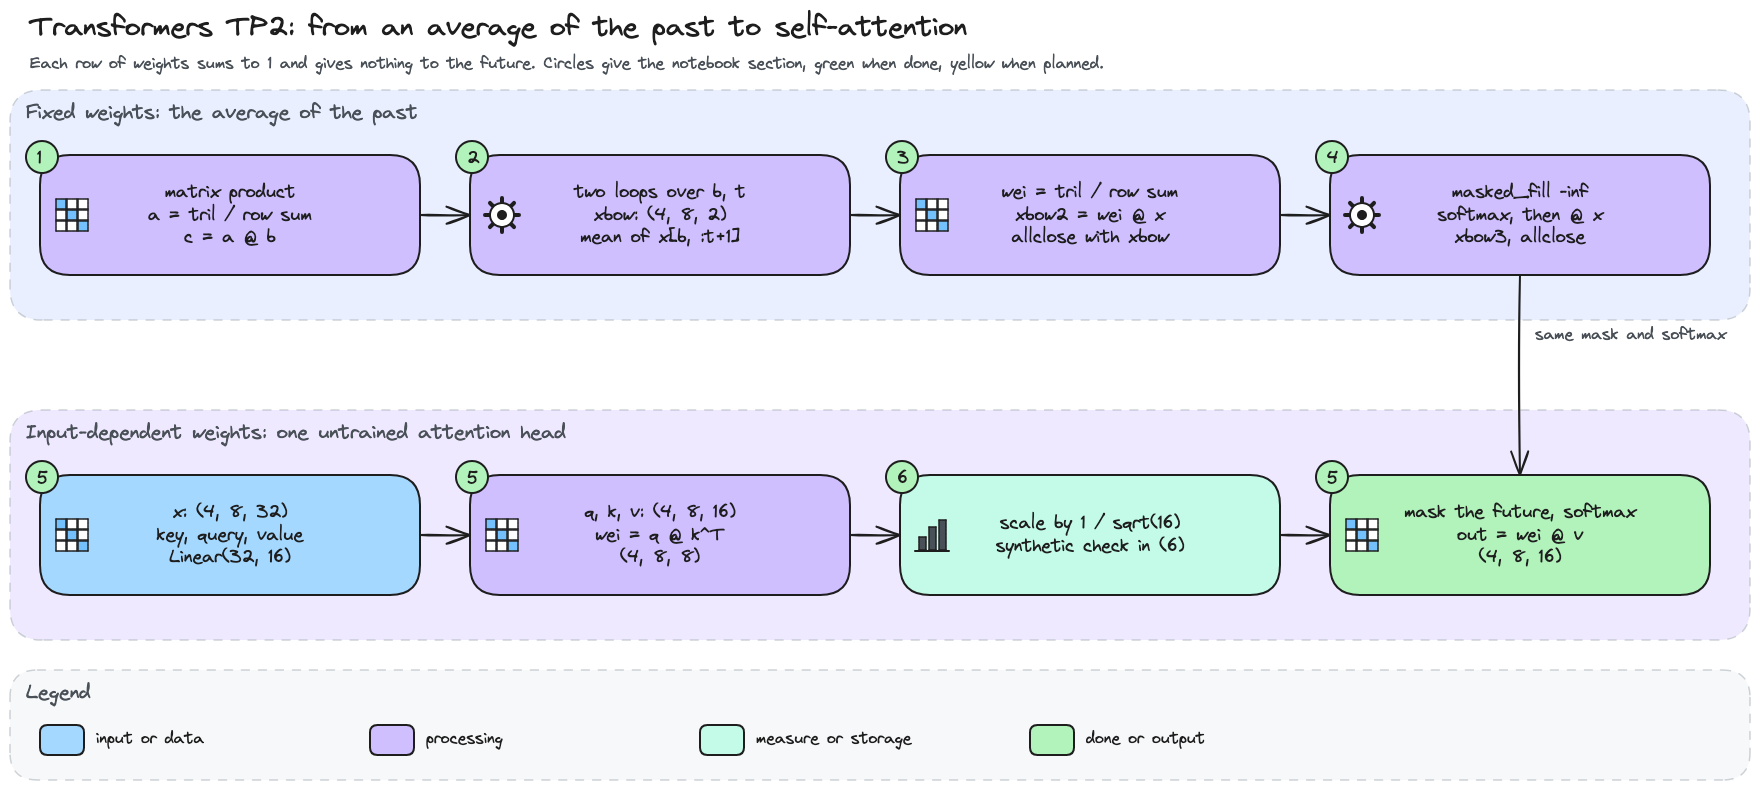

In [1]:
# Workflow diagram: from a fixed average of the past to one attention head (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp2_workflow.png', width=900))

## 0. My problem and what I carry over

I want each position to combine information from its visible prefix, including itself. Reading later positions would reveal information unavailable when generating the next character.

I separate two questions. First, do the implementations compute the intended operation? Then, what changes when the weights depend on the input? The diagram connects these questions to my checks in TP1.

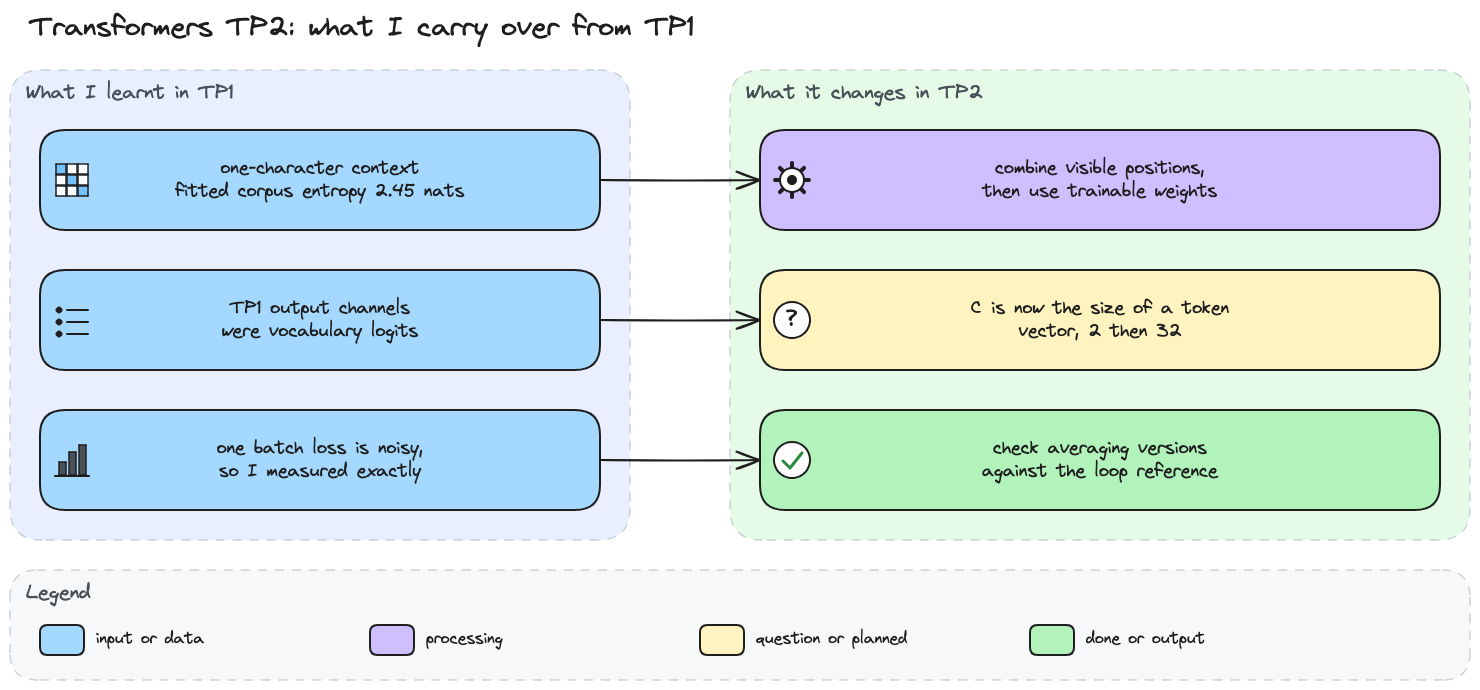

In [2]:
# What I carry over from TP1 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp2_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - A lower-triangular matrix with rows summing to 1 gives exactly the averages of my loops, because both compute the same weighted sum. Sections 2 and 3 check it with `torch.allclose`.
> - Filling the future with −∞ and applying softmax gives the same weights, since exp(−∞) = 0 and softmax divides by the row sum. Section 4 tests it.
> - With random keys and queries, the attention weights are no longer uniform, but each row still sums to 1 and gives nothing to the future. I look at it in section 5.
> - Without scaling, the variance of q·kᵀ grows with the head size, so softmax puts almost all the weight on one token. Section 6 measures this.

### My environment

I use the project's `.venv/bin/python` kernel and the dependencies already used in TP1.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep these small tensors on the CPU because this notebook studies operations without training. The fixed seeds let me repeat the same draws in this environment. They do not guarantee identical timings or floating-point results on every machine.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the original experiments reset their seeds where needed.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Aggregate with a matrix product

Before adding trainable weights, I need to understand what a weight means. I start with three vectors so I can calculate one output by hand and check the matrix product.

I give each visible position an equal, nonnegative weight and make those weights sum to one. This should produce an average while excluding later rows.

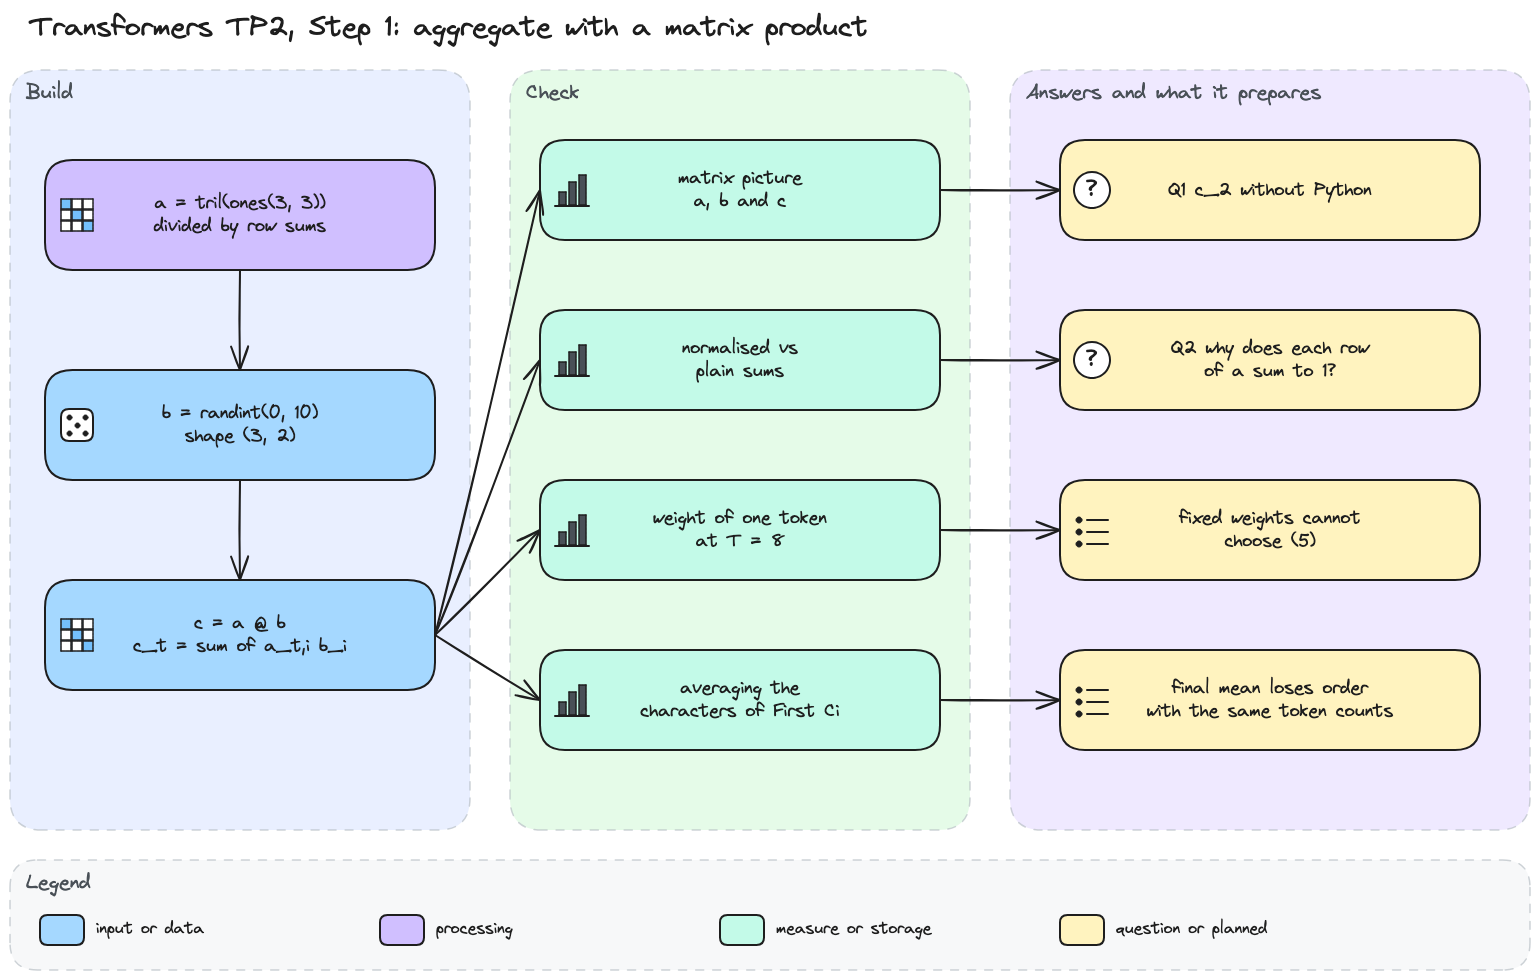

In [4]:
# Step 1 diagram: a, b and c, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step1.png', width=900))

In [5]:
# A lower-triangular matrix with rows summing to 1, a random matrix, and their product.
torch.manual_seed(42)

a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)

b = torch.randint(0, 10, (3, 2)).float()

c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


I read a row of `a` as instructions for combining the rows of `b`. A zero excludes a row, while a positive weight sets its contribution.

What is c₂ without Python? Here the mathematical row numbers start at 1, so c₂ is `c[1]` in Python. I calculate ½ × (2, 7) + ½ × (6, 4) + 0 × (6, 5) = (4, 5.5).

The printed second row agrees. I next draw the matrices to connect each coefficient to the row it uses.

In [6]:
# Tools: draw a small matrix as a heatmap, with its values written in the cells.
import matplotlib.pyplot as plt


def show_matrix(ax: plt.Axes, matrix: torch.Tensor, title: str, digits: int = 2) -> None:
    """Heatmap of a 2D tensor with each value written in its cell."""
    values = matrix.detach().cpu()
    finite = values[values.isfinite()]
    low, high = finite.min().item(), finite.max().item()
    cmap = plt.get_cmap('Blues').copy()
    cmap.set_bad('#e9ecef')  # -inf cells in light grey
    shown = values.masked_fill(~values.isfinite(), float('nan'))
    ax.imshow(shown, cmap=cmap, vmin=low, vmax=high + 0.6 * (high - low or 1))  # light cells
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            ax.text(col, row, f'{values[row, col]:.{digits}f}', ha='center', va='center',
                    fontsize=9)
    ax.set_xticks(range(values.shape[1]))
    ax.set_yticks(range(values.shape[0]))
    ax.set_title(title, fontsize=10)

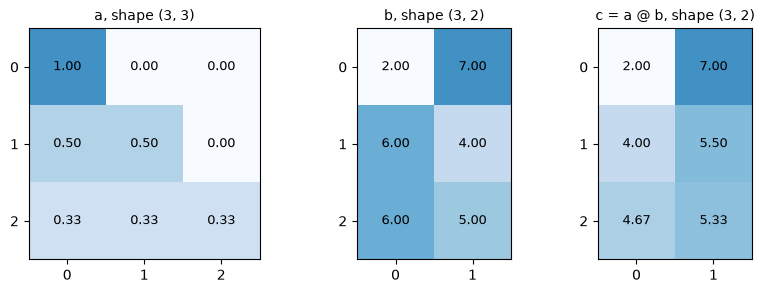

In [7]:
# How does a row of a pick the rows of b? The three matrices with their values.
fig, axes = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [3, 2, 2]})
for ax, matrix, title in ((axes[0], a, 'a, shape (3, 3)'), (axes[1], b, 'b, shape (3, 2)'),
                          (axes[2], c, 'c = a @ b, shape (3, 2)')):
    show_matrix(ax, matrix, title)
plt.show()

The first output copies (2, 7), the second gives (4, 5.5), and the third averages all three vectors into (4.67, 5.33). Each output uses its own prefix.

I now remove only the division by the row sum. Keeping `b` and the triangular pattern fixed lets me distinguish averaging from accumulating more values.

Row sums of a: [1.0, 1.0, 1.0]
c, rows summing to 1: [[2.0, 7.0], [4.0, 5.5], [4.67, 5.33]]
Same product without the division: [[2.0, 7.0], [8.0, 11.0], [14.0, 16.0]]
Range of b per column: from [2.0, 4.0] to [6.0, 7.0]


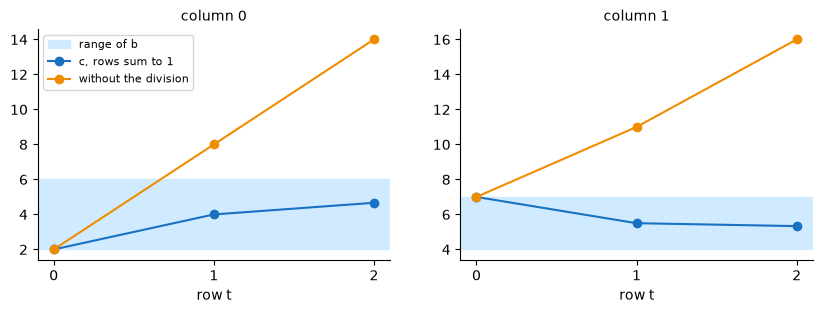

In [8]:
# Why should each row of a sum to 1? Row sums, then the same product without the division.
plain = torch.tril(torch.ones(3, 3)) @ b
rounded = lambda matrix: [[round(value, 2) for value in row] for row in matrix.tolist()]
print(f'Row sums of a: {a.sum(1).tolist()}')
print(f'c, rows summing to 1: {rounded(c)}')
print(f'Same product without the division: {rounded(plain)}')
print(f'Range of b per column: from {b.min(0).values.tolist()} to {b.max(0).values.tolist()}')

rows = torch.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for col, ax in enumerate(axes):
    ax.axhspan(b[:, col].min(), b[:, col].max(), color='#d0ebff', label='range of b')
    ax.plot(rows, c[:, col], marker='o', color='#1971c2', label='c, rows sum to 1')
    ax.plot(rows, plain[:, col], marker='o', color='#f08c00', label='without the division')
    ax.set_xticks(rows)
    ax.set_xlabel('row t')
    ax.set_title(f'column {col}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Dividing each row by its number of ones gives row sums of 1. Together with nonnegative weights, this keeps each output coordinate inside the range of the input coordinates.

The normalised outputs stay between 2 and 6 in the first column and between 4 and 7 in the second. Without normalisation, I obtain (2, 7), (8, 11) and (14, 16). These are prefix sums, whose scale can change simply because the prefix is longer.

Normalisation removes that accumulation, but it still gives every visible token the same influence. I check how that influence changes as the prefix grows.

Weight of the first token in each row: [1.0, 0.5, 0.333, 0.25, 0.2, 0.167, 0.143, 0.125]


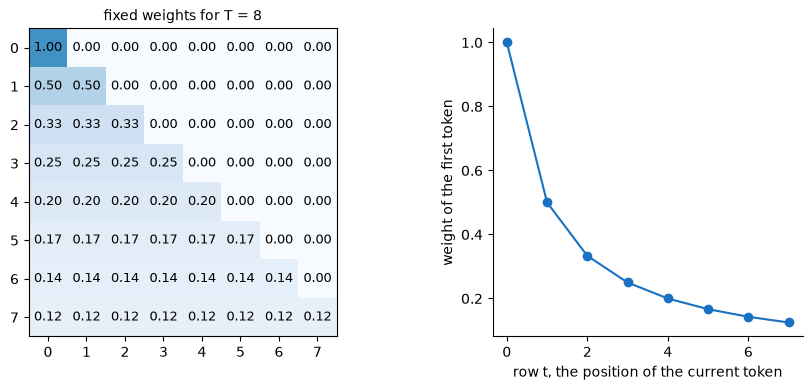

In [9]:
# With fixed weights, how much does one past token count as the context grows? T = 8.
T = 8
weights = torch.tril(torch.ones(T, T))
weights = weights / weights.sum(1, keepdim=True)
print(f'Weight of the first token in each row: {[round(w, 3) for w in weights[:, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [3, 2]})
show_matrix(axes[0], weights, 'fixed weights for T = 8')
axes[1].plot(range(T), weights[:, 0], marker='o', color='#1971c2')
axes[1].set_xlabel('row t, the position of the current token')
axes[1].set_ylabel('weight of the first token')
axes[1].spines[['top', 'right']].set_visible(False)
plt.show()

The first token receives weights of 1, 0.5 and eventually 0.125 in the last row. Its contribution falls because more visible tokens share the same total weight.

These weights depend on position and prefix length alone. A distinctive token receives no special treatment. Before introducing content-dependent weights, I use one-hot character vectors to see what information this average retains.

Characters of the snippet: [' ', 'C', 'F', 'i', 'r', 's', 't']
Last row, share of each character: [0.125, 0.125, 0.125, 0.25, 0.125, 0.125, 0.125]
Same last row for the reversed snippet: True


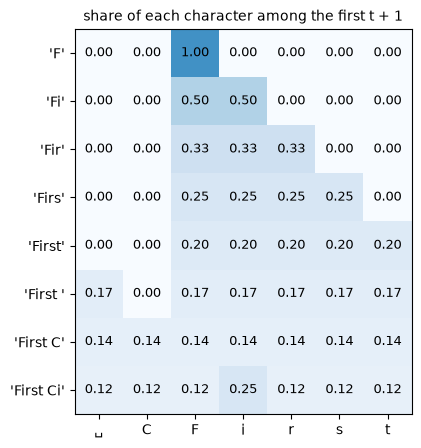

In [10]:
# What does an average of the past keep from real text? One-hot vectors of "First Ci", averaged.
snippet = "First Ci"
symbols = sorted(set(snippet))
one_hot = torch.zeros(len(snippet), len(symbols))
one_hot[torch.arange(len(snippet)), torch.tensor([symbols.index(ch) for ch in snippet])] = 1
averaged = weights @ one_hot
reversed_last = (weights @ one_hot.flip(0))[-1]  # the same characters in reverse order

print(f'Characters of the snippet: {symbols}')
print(f'Last row, share of each character: {[round(v, 3) for v in averaged[-1].tolist()]}')
print(f'Same last row for the reversed snippet: {torch.allclose(averaged[-1], reversed_last)}')

fig, ax = plt.subplots(figsize=(7, 5))
show_matrix(ax, averaged, 'share of each character among the first t + 1')
ax.set_xticks(range(len(symbols)), ['␣' if ch == ' ' else ch for ch in symbols])
ax.set_yticks(range(len(snippet)), [repr(snippet[:t + 1]) for t in range(len(snippet))])
plt.show()

In the final average, `i` has weight 0.25 because it appears twice in `First Ci`. Each other character has weight 0.125. With one-hot inputs, this vector records character proportions.

Reversing the snippet leaves this final average unchanged because it contains the same characters with the same counts. This observation concerns the full-prefix average. Earlier prefix averages can change when the order changes.

I therefore cannot reconstruct the character order from this final vector alone. That limitation motivates a later check of the attention head.

> *My conclusion:*
>
> I can interpret a matrix product as a weighted combination of visible vectors. Nonnegative weights summing to one keep the output within their coordinate ranges, but uniform weights cannot favour a token because of its content.
>
> The character example also shows that the final mean loses order. I next build the same operation with explicit loops so I have a readable reference for later implementations.
>
> My answers to the two questions of this step:
>
> 1. c₂ = ½ × (2, 7) + ½ × (6, 4) = (4, 5.5), which is row 1 in Python.
> 2. Dividing each row of `a` by its number of ones makes its weights sum to 1 and produces an average.

## 2. Average only the past

I want a reference whose indexing I can inspect directly. For each sequence and position, I take the prefix ending at that position and average its token vectors.

The loops make the visible positions explicit. I will check the axis and causality before asking a faster implementation to reproduce them.

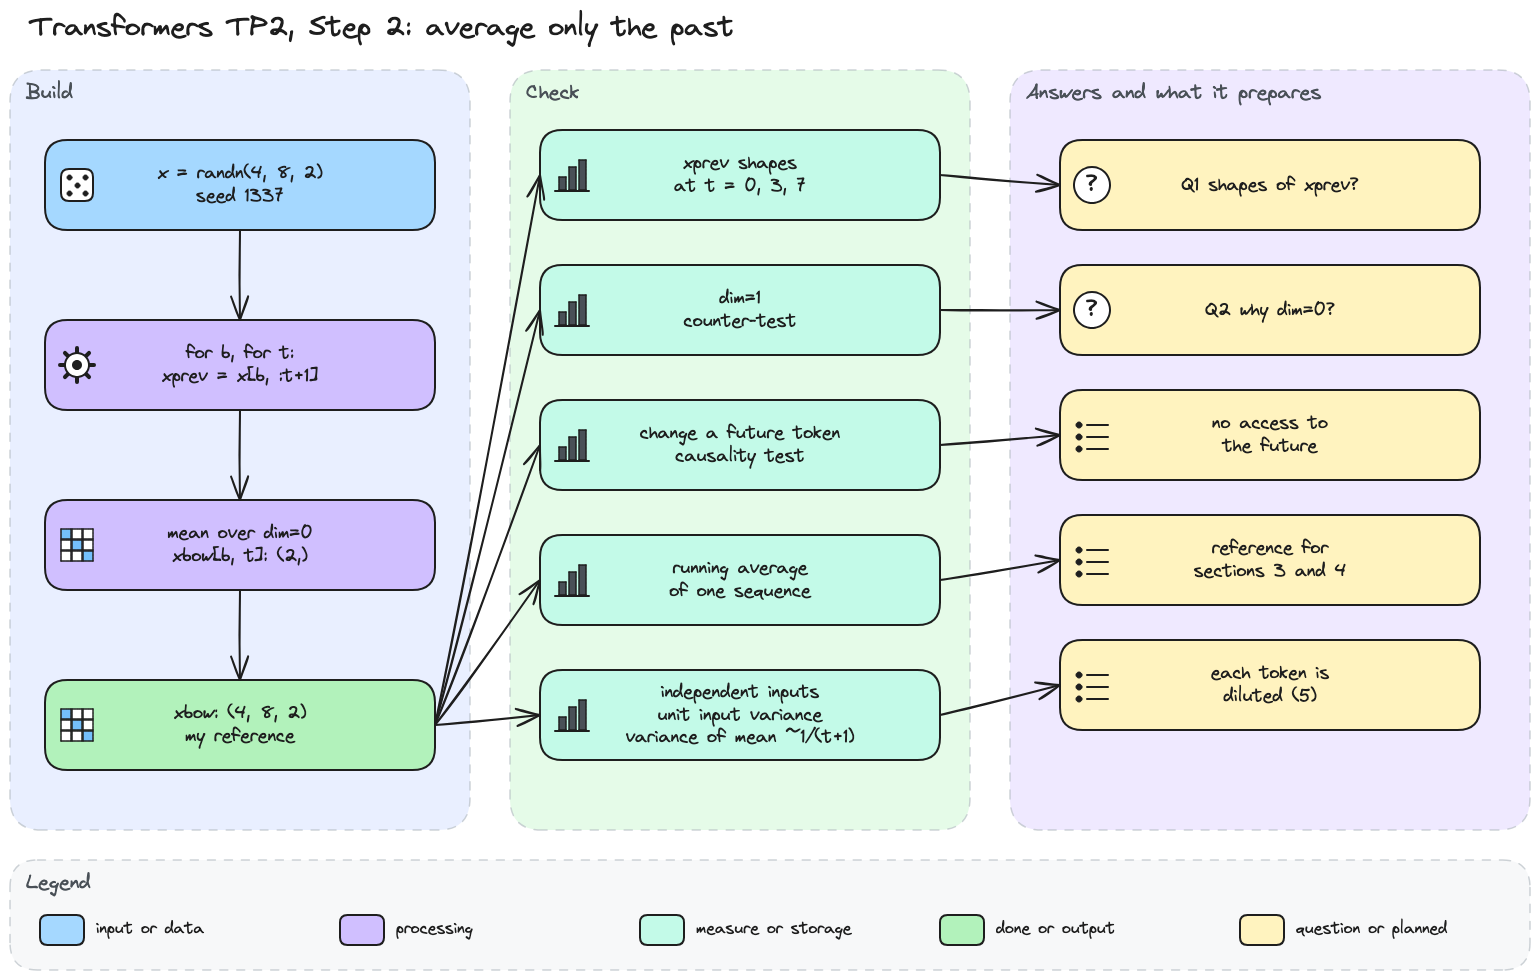

In [11]:
# Step 2 diagram: the two loops, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step2.png', width=900))

In [12]:
# The causal mean with two loops: for each sequence b and position t, the mean of x[b, :t+1].
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]  # (t+1, C)
        xbow[b, t] = torch.mean(xprev, dim=0)

print(f'x: {tuple(x.shape)}, xbow: {tuple(xbow.shape)}')
for t in (0, 3, 7):
    print(f'xprev for t = {t}: {tuple(x[0, :t + 1].shape)}')

x: (4, 8, 2), xbow: (4, 8, 2)
xprev for t = 0: (1, 2)
xprev for t = 3: (4, 2)
xprev for t = 7: (8, 2)


At positions 0, 3 and 7, `xprev` has shapes (1, 2), (4, 2) and (8, 2). Its rows are visible positions and its columns are the two channels of each token.

Taking the mean over dim=0 combines positions while retaining both channels. `xbow` therefore keeps the input shape (4, 8, 2). I check dim=1 on the same prefix to make the difference between the axes concrete.

In [13]:
# What would dim=1 do? At t = 3, the mean over the channels instead of the positions.
xprev = x[0, :4]
print(f'Mean over dim=0: {tuple(xprev.mean(dim=0).shape)}, '
      f'over dim=1: {tuple(xprev.mean(dim=1).shape)}')
try:
    xbow.clone()[0, 3] = xprev.mean(dim=1)  # on a copy, so xbow stays intact
except RuntimeError as error:
    print(f'Writing it into xbow[0, 3] fails: {error}')

Mean over dim=0: (2,), over dim=1: (4,)
Writing it into xbow[0, 3] fails: The expanded size of the tensor (2) must match the existing size (4) at non-singleton dimension 0.  Target sizes: [2].  Tensor sizes: [4]


The mean over dim=1 returns four values because it combines the two channels separately for each of four positions. Those values do not fit the two-channel output slot.

The error catches the shape mismatch in this example. More generally, I choose dim=0 because it matches the meaning of the axes, even when dimensions happen to have equal sizes.

I put the same loops in a helper to reuse this reference in the following checks.

In [14]:
# Tools: the same two loops as a function, to run them on other inputs.
def loop_mean(x: torch.Tensor) -> torch.Tensor:
    """Causal mean with two loops: row t of each sequence is the mean of its rows 0 to t."""
    B, T, C = x.shape
    out = torch.zeros((B, T, C))
    for b in range(B):
        for t in range(T):
            out[b, t] = torch.mean(x[b, :t + 1], dim=0)
    return out


print(f'loop_mean(x) gives xbow again: {torch.equal(loop_mean(x), xbow)}')

loop_mean(x) gives xbow again: True


A correct shape does not establish causality. I change token 5 in a copy of the first sequence while keeping all earlier tokens and the other sequences fixed.

If an earlier output changes, the implementation has used information from its future. The unchanged sequences also check that the batch dimension keeps examples separate.

In [15]:
# Does a position ever read the future? Token 5 of the first sequence raised by 10, loops again.
changed = x.clone()
changed[0, 5] += 10
changed_bow = loop_mean(changed)

moves = (changed_bow[0] - xbow[0]).abs().max(dim=1).values
print(f'Largest change in each row of xbow[0]: {[round(v, 3) for v in moves.tolist()]}')
print(f'Rows 0 to 4 unchanged: {torch.equal(changed_bow[0, :5], xbow[0, :5])}')
print(f'Other sequences unchanged: {torch.equal(changed_bow[1:], xbow[1:])}')

Largest change in each row of xbow[0]: [0.0, 0.0, 0.0, 0.0, 0.0, 1.667, 1.429, 1.25]
Rows 0 to 4 unchanged: True
Other sequences unchanged: True


Changing token 5 leaves rows 0 to 4 and the other sequences unchanged in this test. Rows 5, 6 and 7 move by 1.667, 1.429 and 1.25, matching 10/6, 10/7 and 10/8.

This is consistent with the slice `:t + 1`, which excludes future positions. The test checks the effect on outputs, while the slice explains why that exclusion applies beyond this example.

I next inspect one sequence to see how the same averaging changes the signal over time.

x[0], channel 0: [0.18, -0.36, 0.63, 0.95, 0.36, -1.35, 0.24, -0.92]
xbow[0], channel 0: [0.18, -0.09, 0.15, 0.35, 0.35, 0.07, 0.09, -0.03]


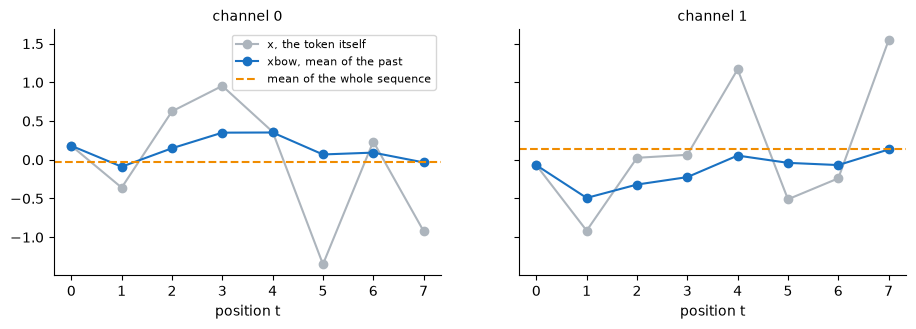

In [16]:
# What does the running mean look like? Both channels of the first sequence, x against xbow.
print(f'x[0], channel 0: {[round(v, 2) for v in x[0, :, 0].tolist()]}')
print(f'xbow[0], channel 0: {[round(v, 2) for v in xbow[0, :, 0].tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for channel, ax in enumerate(axes):
    ax.plot(range(T), x[0, :, channel], marker='o', color='#adb5bd', label='x, the token itself')
    ax.plot(range(T), xbow[0, :, channel], marker='o', color='#1971c2',
            label='xbow, mean of the past')
    ax.axhline(x[0, :, channel].mean(), color='#f08c00', linestyle='--',
               label='mean of the whole sequence')
    ax.set_xlabel('position t')
    ax.set_title(f'channel {channel}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

In channel 0, the first mean copies 0.18. When token 5 falls to -1.35, the mean moves from 0.35 to 0.07 because the new token contributes only part of the prefix.

The final mean is -0.03 and includes all eight tokens. This is a smoothing effect in this sequence, rather than a guarantee that each successive change becomes smaller.

To isolate the effect of prefix length, I next average independent random inputs with unit variance. This controlled input gives me a theoretical reference of 1/(t+1).

Position 0: variance 1.002, 1 / (t+1) = 1.000
Position 1: variance 0.501, 1 / (t+1) = 0.500
Position 3: variance 0.237, 1 / (t+1) = 0.250
Position 7: variance 0.124, 1 / (t+1) = 0.125


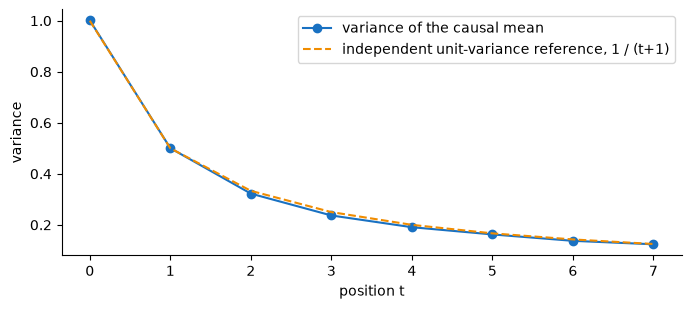

In [17]:
# How much of one token survives in the mean? Variance of the causal mean of many random sequences.
torch.manual_seed(RANDOM_STATE)
many = torch.randn(2000, T, C)
variance = loop_mean(many).var(dim=(0, 2))
for t in (0, 1, 3, 7):
    print(f'Position {t}: variance {variance[t]:.3f}, 1 / (t+1) = {1 / (t + 1):.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), variance, marker='o', color='#1971c2', label='variance of the causal mean')
ax.plot(range(T), [1 / (t + 1) for t in range(T)], linestyle='--', color='#f08c00',
        label='independent unit-variance reference, 1 / (t+1)')
ax.set_xlabel('position t')
ax.set_ylabel('variance')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The measured variances are 1.002, 0.501, 0.237 and 0.124 at positions 0, 1, 3 and 7. They are close to the corresponding 1/(t+1) reference.

For independent inputs of unit variance, averaging t+1 values divides the variance by t+1. That argument does not transfer unchanged to correlated character representations. The fixed coefficient 1/(t+1), however, follows directly from the averaging rule.

This resembles the masked mean in my speaker-classification notebook, which ignores padding. Here the visible set is a prefix, and I still have no way to choose weights from its content.

> *My conclusion:*
>
> The loops make both choices explicit. I average the position axis, and I stop the prefix at the current token. The perturbation test agrees with that causal indexing.
>
> The synthetic variance experiment explains one consequence of uniform averaging under independent inputs. It does not measure how much useful language information an average retains. I keep the loops as the reference for sections 3 and 4.
>
> My answers to the two questions of this step:
>
> 1. `xprev` has shape (t+1, C), giving (1, 2), (4, 2) and (8, 2) in the displayed examples.
> 2. dim=0 averages positions while keeping channels separate. dim=1 averages channels within each position.

## 3. Vectorise with a triangular matrix

I now change the implementation while keeping the input and averaging rule fixed. This comparison asks whether one matrix product reproduces the reference loops.

I check agreement before measuring speed. A faster operation would be irrelevant if it mixed the wrong positions or channels.

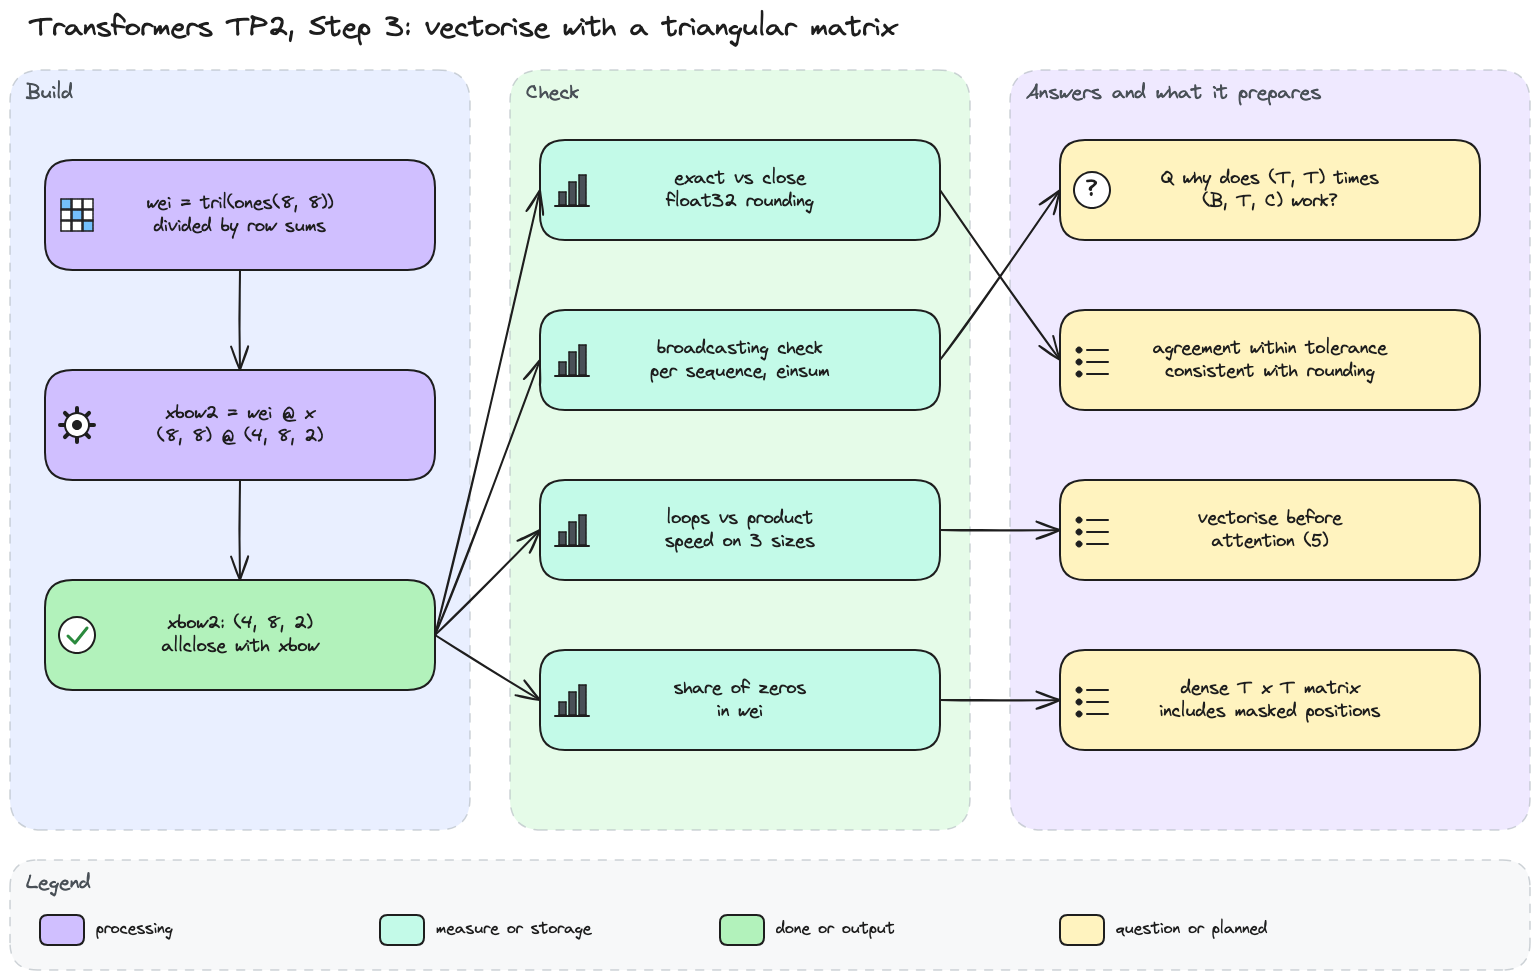

In [18]:
# Step 3 diagram: the triangular product, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp2_step3.png', width=900))

In [19]:
# The same causal mean in one matrix product, checked against the loops of section 2.
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x
print(torch.allclose(
    xbow, xbow2, atol=1e-6
))

print(f'wei: {tuple(wei.shape)}, x: {tuple(x.shape)}, xbow2: {tuple(xbow2.shape)}')
print(f'Same matrix as the weights of section 1: {torch.equal(wei, weights)}')

True
wei: (8, 8), x: (4, 8, 2), xbow2: (4, 8, 2)
Same matrix as the weights of section 1: True


The comparison passes, and both outputs have shape (4, 8, 2). The shared 8 × 8 weight matrix also matches the one from section 1.

This supports my hypothesis of equivalent averaging on this input. However, `allclose` checks a tolerance rather than exact equality. I inspect the largest difference before deciding what agreement means here.

In [20]:
# Exactly equal, or only close? The largest gap between the loops and the product.
print(f'torch.equal(xbow, xbow2): {torch.equal(xbow, xbow2)}')
print(f'Largest difference: {(xbow - xbow2).abs().max().item():.2e}')
print(f'Machine epsilon of float32: {torch.finfo(torch.float32).eps:.2e}')
print('allclose check: absolute tolerance 1e-6, default relative tolerance 1e-5')

torch.equal(xbow, xbow2): False
Largest difference: 1.19e-07
Machine epsilon of float32: 1.19e-07
allclose check: absolute tolerance 1e-6, default relative tolerance 1e-5


The outputs differ by at most 1.19e-07, which matches the displayed float32 epsilon. The formulas use the same weights, but multiplication and summation can round differently when their order changes.

This small gap is consistent with rounding. Epsilon describes spacing near 1, rather than a universal error bound. Its value alone cannot prove that an implementation is correct.

The existing check accepts `abs(a - b) <= 1e-6 + 1e-5 * abs(b)`. It combines the chosen absolute tolerance with PyTorch's default relative tolerance. I also inspect shapes and indexing because a tolerance check can miss sufficiently small errors.

Next I make the batch broadcasting explicit without changing the input or weights.

In [21]:
# Why does a (T, T) matrix multiply a (B, T, C) tensor? The same product, written three other ways.
per_sequence = torch.stack([wei @ x[b] for b in range(B)])
explicit = torch.einsum('tu,buc->btc', wei, x)  # sum over the past positions u, for every b and c
expanded = wei.expand(B, T, T) @ x

print(f'wei @ x[b] for each sequence, stacked: {torch.equal(per_sequence, xbow2)}')
print(f'einsum over the positions: {torch.equal(explicit, xbow2)}')
print(f'wei expanded to {tuple(wei.expand(B, T, T).shape)}: {torch.equal(expanded, xbow2)}')

wei @ x[b] for each sequence, stacked: True
einsum over the positions: True
wei expanded to (4, 8, 8): True


PyTorch applies the same (T, T) matrix to each sequence of the (B, T, C) input. It behaves as though the weights had a batch dimension, without requiring separate stored copies.

The per-sequence products, expanded view and einsum all agree exactly in this run. This helps me connect the broadcasting rule to independent sequences and channels.

With correctness checked, I time the existing loops and product on the same tensors at three sizes. The matrix is prepared outside the timing, so this comparison measures applying it.

B, T, C = (4, 8, 2): 32 means, loops 0.145 ms, product 0.0025 ms, 59 times faster
B, T, C = (32, 64, 32): 2,048 means, loops 8.511 ms, product 0.0385 ms, 221 times faster
B, T, C = (64, 256, 64): 16,384 means, loops 74.707 ms, product 0.6397 ms, 117 times faster


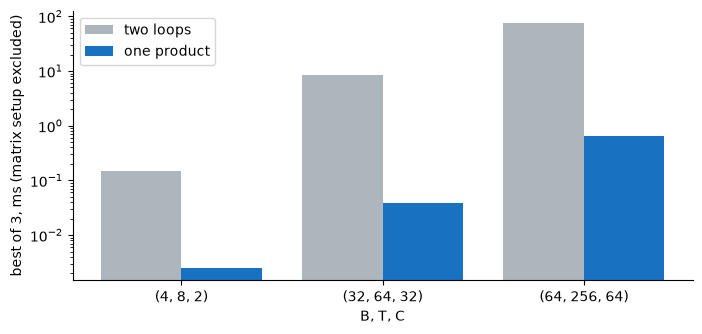

In [22]:
# Is the product worth it? Best of 3 timings for the loops and for the product, on three sizes.
import timeit

SIZES = [(4, 8, 2), (32, 64, 32), (64, 256, 64)]
timings = {}
for size in SIZES:
    sample = torch.randn(size)
    causal = torch.tril(torch.ones(size[1], size[1]))
    causal = causal / causal.sum(1, keepdim=True)
    loops = min(timeit.repeat(lambda: loop_mean(sample), number=1, repeat=3))
    product = min(timeit.repeat(lambda: causal @ sample, number=10, repeat=3)) / 10
    timings[size] = (loops * 1e3, product * 1e3)
    print(f'B, T, C = {size}: {size[0] * size[1]:,} means, loops {loops * 1e3:.3f} ms, '
          f'product {product * 1e3:.4f} ms, {loops / product:.0f} times faster')

labels = [str(size) for size in SIZES]
positions = torch.arange(len(SIZES))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(positions - 0.2, [loops for loops, _ in timings.values()], 0.4, color='#adb5bd',
       label='two loops')
ax.bar(positions + 0.2, [product for _, product in timings.values()], 0.4, color='#1971c2',
       label='one product')
ax.set_xticks(positions, labels)
ax.set_yscale('log')
ax.set_xlabel('B, T, C')
ax.set_ylabel('best of 3, ms (matrix setup excluded)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The product is faster at all three sizes in this run. The chart uses the best of three measurements for each case. These minima describe a small benchmark, rather than a stable speed guarantee.

The product uses an optimised matrix routine while the loops repeatedly invoke a mean operation. There are B × T means, but their prefixes grow with T, so their total work is not described by that count alone.

I retain the loops for checking the operation and use the product to express it compactly. I next inspect the dense matrix's storage, since faster execution does not remove its T × T shape.

In [23]:
# How much of wei is zero? The product still multiplies by every one of them.
print(f'Zeros in wei: {(wei == 0).sum().item()} of {wei.numel()}')
for size in (8, 64, 256):
    zeros = size * (size - 1) // 2
    print(f'T = {size}: {zeros:,} zeros of {size * size:,} weights, {100 * zeros / size**2:.2f}%')

Zeros in wei: 28 of 64
T = 8: 28 zeros of 64 weights, 43.75%
T = 64: 2,016 zeros of 4,096 weights, 49.22%
T = 256: 32,640 zeros of 65,536 weights, 49.80%


For T = 8, 28 of 64 entries are zero, or 43.75%. The fraction reaches 49.22% at T = 64 and 49.80% at T = 256.

This implementation stores a dense matrix and uses a dense product despite the masked entries. The counts describe unused positions in that matrix, not a measurement of wasted runtime. They do not establish the cost of every possible attention implementation.

> *My conclusion:*
>
> The product reproduces the loop means within the stated tolerance on this input. My initial expectation of exact agreement needs a numerical qualification because the floating-point outputs differ slightly.
>
> Broadcasting applies the same weights to each sequence, and the timing comparison measures the benefit of this implementation locally. I next keep the operation fixed again and change how its weights are constructed.
>
> My answer to the question of this step:
>
> - PyTorch broadcasts the (T, T) matrix across B sequences. Each sequence receives (T, T) @ (T, C), giving a (T, C) output.

## 4. The same weights from a mask and softmax

I want a construction that can later accept unequal scores. I first keep all visible scores equal, so any difference from the causal mean would reveal a problem with masking or normalisation.

The mask decides which positions are allowed. Softmax assigns their relative weights.

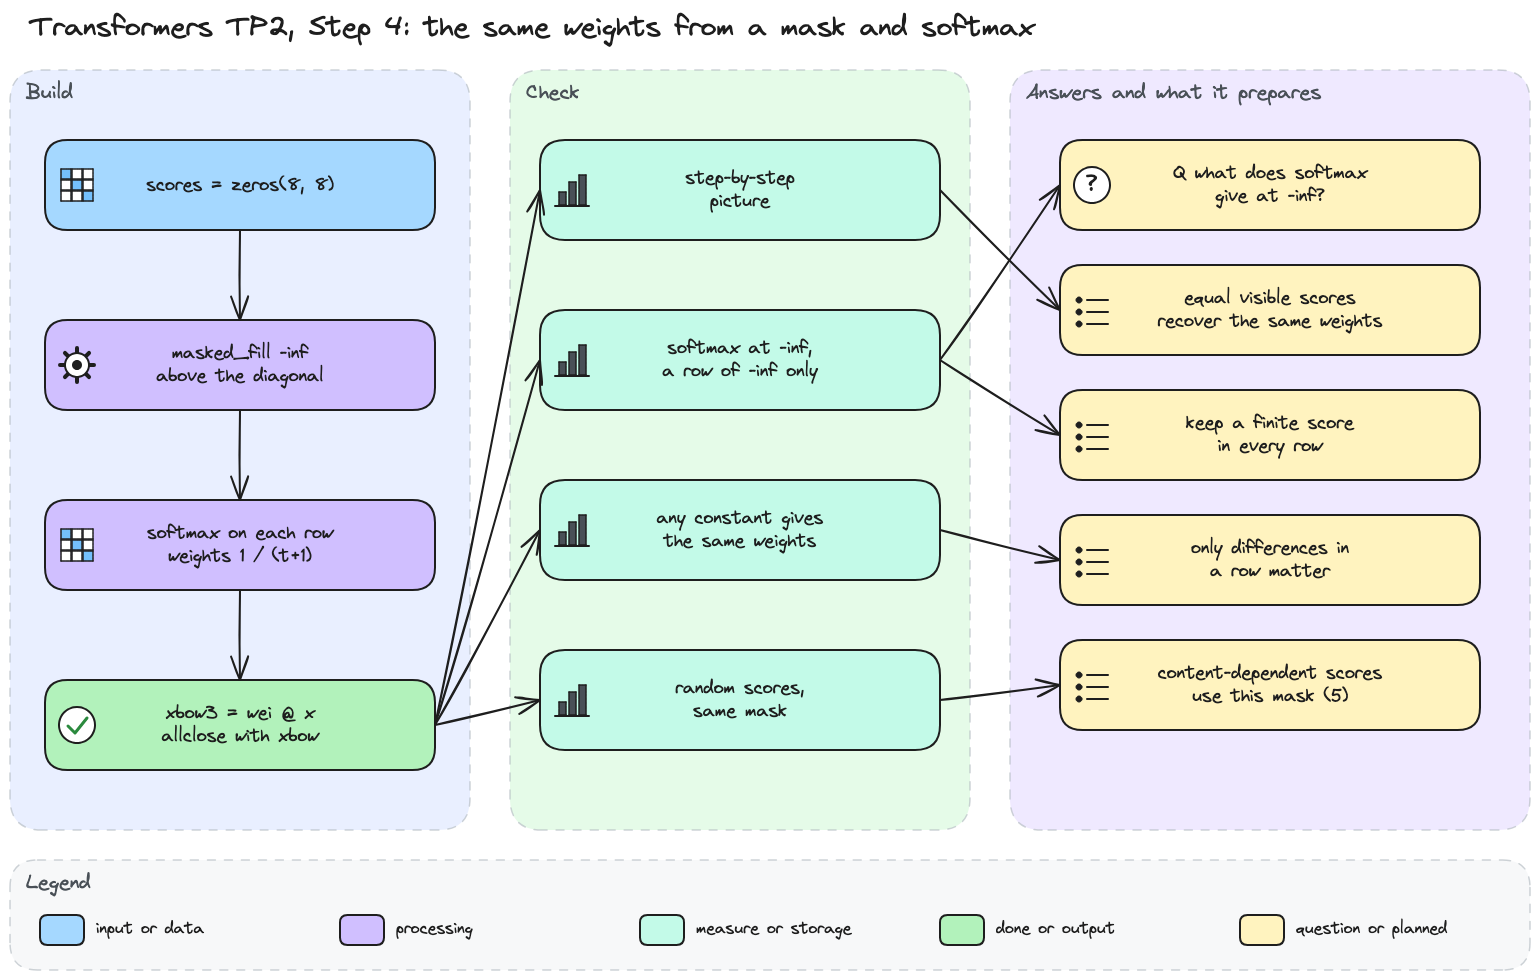

In [24]:
# Step 4 diagram: zeros, mask, softmax, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp2_step4.png', width=900))

In [25]:
# The same weights from a mask and softmax: zeros, -inf on the future, then softmax on each row.
import torch.nn.functional as F

tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

xbow3 = wei @ x
print(torch.allclose(
    xbow, xbow3, atol=1e-6
))

print(f'Exactly the weights of section 3: {torch.equal(wei, weights)}')

True
Exactly the weights of section 3: True


The mean passes the tolerance check, and the weights equal the earlier triangular weights exactly in this run. Equal visible scores therefore recover the fixed average.

I separate the score, mask and softmax stages next. This will help me locate the effect of each operation before introducing unequal scores.

Row sums after softmax: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0000001192092896, 1.0]


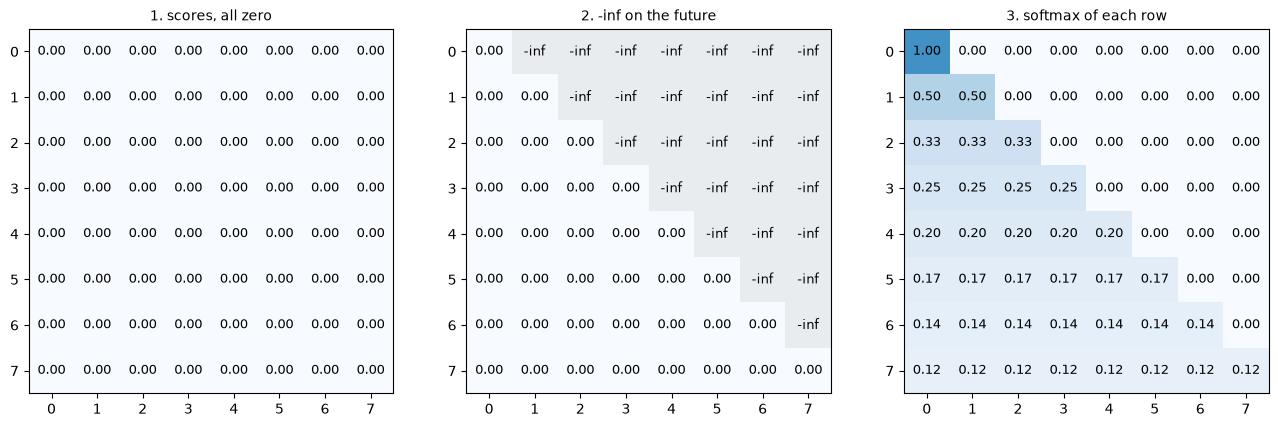

In [26]:
# What happens at each move? The scores at zero, the masked scores, then the weights after softmax.
scores = torch.zeros((T, T))
masked = scores.masked_fill(tril == 0, float('-inf'))
print(f'Row sums after softmax: {wei.sum(dim=1).tolist()}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, matrix, title in ((axes[0], scores, '1. scores, all zero'),
                          (axes[1], masked, '2. -inf on the future'),
                          (axes[2], wei, '3. softmax of each row')):
    show_matrix(ax, matrix, title)
plt.show()

The mask replaces future scores with −∞ and keeps the current position and its past visible. Softmax assigns equal weights to those visible positions because their scores are equal.

The printed row sums are 1 apart from float32 rounding in one row. The heatmap rounds the last row's weight to 0.12, while its unrounded value is 1/8.

I now calculate a short row explicitly to see how a masked score becomes a zero weight.

In [28]:
# Work through exponentiation and normalisation, including a fully masked row.
minus_inf = float('-inf')
demo_masked_row = torch.tensor([0.0, 0.0, minus_inf])
demo_exponentials = demo_masked_row.exp()
demo_denominator = demo_exponentials.sum()
demo_normalised = demo_exponentials / demo_denominator
assert torch.allclose(demo_normalised, F.softmax(demo_masked_row, dim=-1))
print(f'exp(-inf) = {torch.exp(torch.tensor(minus_inf)).item()}')
print(f'Exponentials: {demo_exponentials.tolist()}, sum: {demo_denominator.item()}')
print(f'softmax([0, 0, -inf]) = {demo_normalised.tolist()}')
print(f'softmax([-inf, -inf, -inf]) = {F.softmax(torch.full((3,), minus_inf), dim=-1).tolist()}')

exp(-inf) = 0.0
Exponentials: [1.0, 1.0, 0.0], sum: 2.0
softmax([0, 0, -inf]) = [0.5, 0.5, 0.0]
softmax([-inf, -inf, -inf]) = [nan, nan, nan]


For the short row, exponentiation gives [1, 1, 0]. Their sum is 2, so normalisation gives [0.5, 0.5, 0]. The assertion checks this hand calculation against PyTorch.

The fully masked row returns NaNs because no valid probability distribution remains. The direct exponential formula would divide by zero, and a numerically stabilised softmax also encounters undefined arithmetic on an entirely infinite row.

Keeping the diagonal visible gives every row at least one finite score here. More generally, I need at least one allowed finite score per row. I next keep the mask fixed and change the shared value of the visible scores.

In [30]:
# Why zeros? Other constants through the same mask and softmax.
for value in (0.0, 5.0, -3.0):
    constant = F.softmax(torch.full((T, T), value).masked_fill(tril == 0, minus_inf), dim=-1)
    print(f'Scores all equal to {value}: same weights {torch.equal(constant, wei)}, '
          f'largest gap {(constant - wei).abs().max().item():.1e}')

Scores all equal to 0.0: same weights True, largest gap 0.0e+00
Scores all equal to 5.0: same weights True, largest gap 0.0e+00
Scores all equal to -3.0: same weights True, largest gap 0.0e+00


The constants 0, 5 and −3 produce the same weights in this example. Adding the same finite constant to every visible score multiplies numerator and denominator by the same factor, which cancels.

Zero is therefore a convenient starting value. Equality between visible scores is what makes the row uniform. I next use unequal random scores while retaining the same mask.

Row sums: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Everything above the diagonal is zero: True
Last row: [0.016, 0.066, 0.06, 0.125, 0.058, 0.403, 0.019, 0.254]


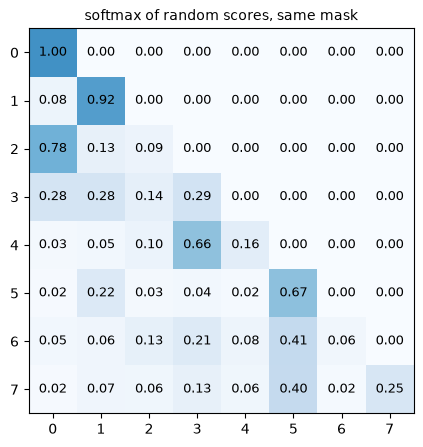

In [31]:
# What if the scores were not all equal? Random scores through the same mask and softmax.
torch.manual_seed(RANDOM_STATE)
random_wei = F.softmax(torch.randn(T, T).masked_fill(tril == 0, minus_inf), dim=-1)
print(f'Row sums: {[round(total, 3) for total in random_wei.sum(dim=1).tolist()]}')
print(f'Everything above the diagonal is zero: {(random_wei.triu(1) == 0).all().item()}')
print(f'Last row: {[round(weight, 3) for weight in random_wei[-1].tolist()]}')

fig, ax = plt.subplots(figsize=(6, 5))
show_matrix(ax, random_wei, 'softmax of random scores, same mask')
plt.show()

The random-score example still has row sums of 1 and zero future weights. Its last row assigns 0.403 to token 5 and 0.016 to token 0.

This shows that causal masking does not require uniform weights. It does not show that the preferred token is useful, since these scores were sampled without a learning objective.

The mask excludes future positions, much as a padding mask excludes padding in my speaker-classification notebook. Section 5 will make scores depend on token vectors while retaining this normalisation.

> *My conclusion:*
>
> Equal finite scores and a causal mask recover the same uniform weights in this run. Unequal scores change the distribution while preserving its allowed positions, provided each row retains a finite score.
>
> This separates the structural constraint from the choice of weights. I can now replace the scores without changing what each row is allowed to read.
>
> My answer to the question of this step:
>
> - A −∞ score receives weight zero when the row contains valid finite scores. Softmax normalises the remaining entries, while a fully masked row gives NaNs here.

## 5. Compute attention weights

I now want weights that respond to the token vectors. Queries and keys provide a score for each pair, while values provide the vectors that will be combined.

These projections have trainable parameters, but I initialise them randomly and perform no training. This experiment checks their roles and shapes. It cannot tell me whether the weights identify useful linguistic context.

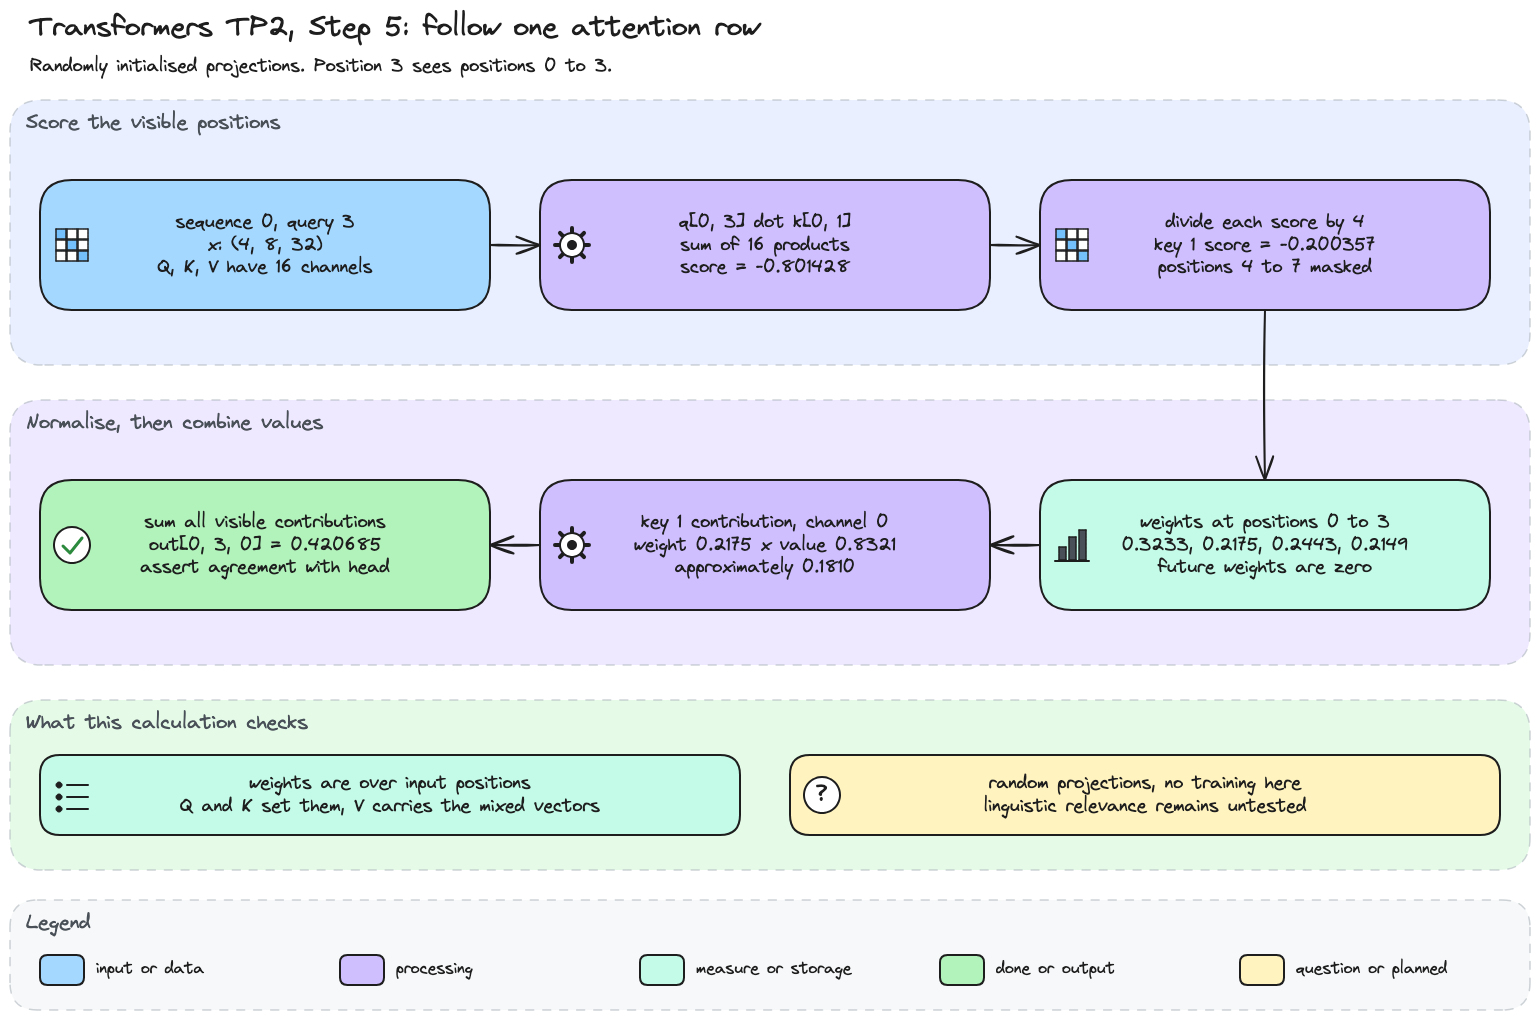

In [32]:
# Step 5 diagram: one attention head, its shapes, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp2_step5.png', width=900))

In [33]:
# One attention head: keys, queries and values from x, then masked and normalised scores.
import torch.nn as nn

torch.manual_seed(1337)  # the TP2 seed, as in section 2
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)                      # (B,T,16)
q = query(x)                    # (B,T,16)
wei = q @ k.transpose(-2, -1)   # (B,T,T)
wei = wei * head_size**-0.5     # scaling, studied in section 6
wei = wei.masked_fill(tril[:T, :T] == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v                   # (B,T,16)

In [34]:
# Which shape means what? B sequences, T positions, C channels per token, d_h channels per head.
for name, tensor in (('x', x), ('k', k), ('q', q), ('k transposed', k.transpose(-2, -1)),
                     ('wei', wei), ('v', v), ('out', out)):
    print(f'{name}: {tuple(tensor.shape)}')

parameters = sum(p.numel() for layer in (key, query, value) for p in layer.parameters())
print(f'Parameters of key, query and value: {parameters:,}')
print(f'Rows of wei sum to 1: {torch.allclose(wei.sum(dim=-1), torch.ones(B, T))}, '
      f'nothing above the diagonal: {(wei.triu(1) == 0).all().item()}')

x: (4, 8, 32)
k: (4, 8, 16)
q: (4, 8, 16)
k transposed: (4, 16, 8)
wei: (4, 8, 8)
v: (4, 8, 16)
out: (4, 8, 16)
Parameters of key, query and value: 1,536
Rows of wei sum to 1: True, nothing above the diagonal: True


I have 4 sequences with 8 positions and 32 channels per token. Each projection maps those channels to 16, giving queries, keys and values of shape (4, 8, 16).

The query-key product gives one 8 × 8 score matrix per sequence. The output has shape (4, 8, 16) because each row combines value vectors. The three projections contain 1,536 parameters.

The row-sum and future-weight checks pass. To connect these shapes to a calculation, I follow position 3 of sequence 0 through the head and reconstruct one output channel.

In [36]:
# Reconstruct one attention row and one output channel without changing the head.
demo_query = q[0, 3].detach()
demo_keys = k[0].detach()
demo_values = v[0].detach()
demo_scores = (demo_keys * demo_query).sum(dim=-1)
demo_scaled = demo_scores / head_size**0.5
demo_masked = demo_scaled.masked_fill(torch.arange(T) > 3, float('-inf'))
demo_row = demo_masked.softmax(dim=-1)
demo_terms = demo_row * demo_values[:, 0]
demo_output = demo_terms.sum()
assert torch.allclose(demo_row, wei[0, 3].detach(), atol=1e-6)
assert torch.allclose(demo_output, out[0, 3, 0].detach(), atol=1e-6)
print(f'Query 3 against key 1, sum of 16 component products: {demo_scores[1]:.6f}')
print(f'Raw scores: {[round(s, 4) for s in demo_scores.tolist()]}')
print(f'Scaled scores: {[round(s, 4) for s in demo_scaled.tolist()]}')
print(f'Masked scores: {[round(s, 4) for s in demo_masked.tolist()]}')
print(f'Weights: {[round(w, 4) for w in demo_row.tolist()]}')
print(f'Value channel 0: {[round(v, 4) for v in demo_values[:, 0].tolist()]}')
print(f'Weighted contributions: {[round(v, 4) for v in demo_terms.tolist()]}')
print(f'Sum: {demo_output:.6f}, out[0, 3, 0]: {out[0, 3, 0].item():.6f}')

Query 3 against key 1, sum of 16 component products: -0.801428
Raw scores: [0.7836, -0.8014, -0.3368, -0.8496, -0.5602, -1.1701, -1.2927, -1.026]
Scaled scores: [0.1959, -0.2004, -0.0842, -0.2124, -0.1401, -0.2925, -0.3232, -0.2565]
Masked scores: [0.1959, -0.2004, -0.0842, -0.2124, -inf, -inf, -inf, -inf]
Weights: [0.3233, 0.2175, 0.2443, 0.2149, 0.0, 0.0, 0.0, 0.0]
Value channel 0: [-0.1571, 0.8321, 0.6035, 0.6657, 0.1536, -0.892, -0.4849, 0.2042]
Weighted contributions: [-0.0508, 0.181, 0.1474, 0.1431, 0.0, -0.0, -0.0, 0.0]
Sum: 0.420685, out[0, 3, 0]: 0.420685


For query 3 and key 1, the dot product is about -0.8014. Division by 4 gives -0.2004, and normalising the visible scores assigns key 1 a weight of 0.2175.

Its value in channel 0 is 0.8321, so its contribution is about 0.1810. Adding all four visible contributions gives 0.420685. The assertions compare unrounded calculations with the existing head.

The mask removes positions 4 through 7 before normalisation. These weights form a distribution over input positions, unlike TP1's next-character probabilities. I now inspect all rows to see how their visible sets differ.

Last row, wei[0][7]: [0.084, 0.12, 0.108, 0.154, 0.109, 0.115, 0.156, 0.155]


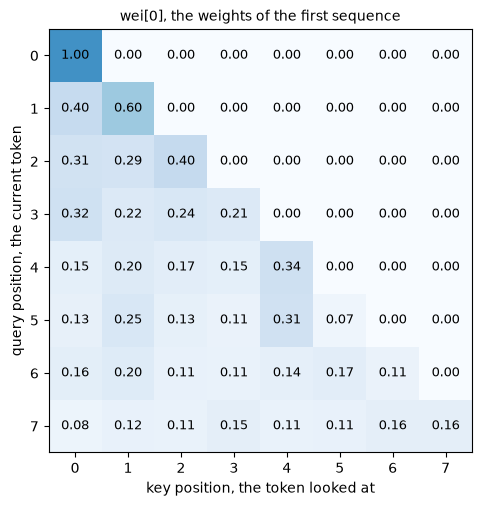

In [38]:
# The weights of the first sequence, wei[0]. Which row belongs to the last token?
print(f'Last row, wei[0][{T - 1}]: {[round(weight, 3) for weight in wei[0, -1].tolist()]}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
show_matrix(ax, wei[0], 'wei[0], the weights of the first sequence')
ax.set_xlabel('key position, the token looked at')
ax.set_ylabel('query position, the current token')
plt.show()

Row 7 of `wei[0]` belongs to the last token because rows index queries and columns index keys. It is the only row that sees all eight positions.

Its weights range from 0.084 to 0.156, compared with 0.125 for a uniform row. Row 0 must assign all its weight to itself because no other position is visible.

The unequal weights support my hypothesis, but the differences look modest. I use entropy to describe their concentration relative to the uniform reference for each prefix length.

Row 1: entropy 0.672, uniform ln(2) = 0.693
Row 4: entropy 1.552, uniform ln(5) = 1.609
Row 7: entropy 2.059, uniform ln(8) = 2.079


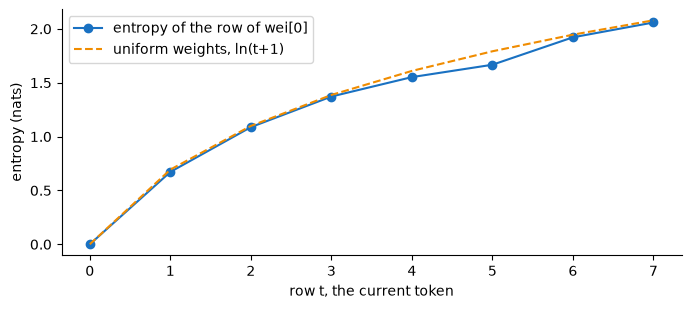

In [39]:
# How far from uniform are these weights? Entropy of each row against ln(t+1), the uniform case.
import math

weights0 = wei[0].detach()
entropy = -(weights0 * torch.log(weights0.clamp_min(1e-12))).sum(dim=1)  # 0 * log 0 counted as 0
for t in (1, 4, 7):
    print(f'Row {t}: entropy {entropy[t]:.3f}, uniform ln({t + 1}) = {math.log(t + 1):.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), entropy, marker='o', color='#1971c2', label='entropy of the row of wei[0]')
ax.plot(range(T), [math.log(t + 1) for t in range(T)], linestyle='--', color='#f08c00',
        label='uniform weights, ln(t+1)')
ax.set_xlabel('row t, the current token')
ax.set_ylabel('entropy (nats)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Entropy adds the terms −w ln(w) across the row, with zero-weight terms counted as zero. It is ln(t+1) for a uniform visible prefix and zero when one position receives all the weight.

Row 7 has entropy 2.059 against the uniform reference of 2.079. Row 4 gives 1.552 against 1.609. These rows are nonuniform while remaining close to their references, which is consistent with my original hypothesis.

Concentration does not measure usefulness. Training could favour sharper or broader weights depending on the task. I next hold the input and query projection fixed while replacing either keys or values.

In [40]:
# Why mix v and not k? Compare key and value, then swap each layer for another random one.
cosine = F.cosine_similarity(k[0], v[0], dim=-1)
print(f'Cosine between key and value, token by token: {[round(c, 2) for c in cosine.tolist()]}')

torch.manual_seed(RANDOM_STATE)
other_key = nn.Linear(C, head_size, bias=False)
other_value = nn.Linear(C, head_size, bias=False)
other_scores = (q @ other_key(x).transpose(-2, -1)) * head_size**-0.5
other_wei = F.softmax(other_scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
print(f'Another key layer: the weights move by up to {(other_wei - wei).abs().max().item():.3f}')
print(f'Another value layer: same weights, the output moves by up to '
      f'{(wei @ other_value(x) - out).abs().max().item():.2f}')

Cosine between key and value, token by token: [0.02, -0.08, -0.02, -0.1, 0.14, 0.57, 0.39, -0.1]
Another key layer: the weights move by up to 0.554
Another value layer: same weights, the output moves by up to 2.70


Replacing the key projection changes the weights by up to 0.554. Replacing only the value projection leaves those weights unchanged and changes the output by up to 2.70.

This agrees with the computation graph. Queries and keys determine the weights, while values determine the vectors being combined. Separate projections allow matching features and transferred features to differ.

The cosine measurements show that the initial key and value vectors differ here. They do not establish that separate projections improve a trained model. I next shuffle the earlier inputs while holding the final query token fixed.

In [41]:
# Does the head know the order? Shuffle the 7 past tokens of the first sequence, keep the last one.
torch.manual_seed(RANDOM_STATE)
order = torch.cat([torch.randperm(T - 1), torch.tensor([T - 1])])
shuffled = x[0, order].unsqueeze(0)
shuffled_scores = query(shuffled) @ key(shuffled).transpose(-2, -1) * head_size**-0.5
shuffled_wei = F.softmax(shuffled_scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
shuffled_out = shuffled_wei @ value(shuffled)

print(f'New order of the tokens: {order.tolist()}')
print(f'Same output for the last token: '
      f'{torch.allclose(shuffled_out[0, -1], out[0, -1], atol=1e-6)}')
print(f'Largest final-output difference: '
      f'{(shuffled_out[0, -1] - out[0, -1]).abs().max().item():.2e}')

New order of the tokens: [1, 6, 3, 5, 4, 0, 2, 7]
Same output for the last token: True
Largest final-output difference: 5.96e-08


The final output agrees within tolerance after the seven preceding token vectors are shuffled. The final query and its visible set stay fixed, while keys and values are permuted together.

For this head without positional information, that permutation preserves the final weighted sum. Earlier positions have different visible prefixes after the shuffle, so the test does not establish invariance of the whole sequence.

I therefore need another source of position information if this representation must distinguish the order within that visible set. Position embeddings are one option explored later.

> *My conclusion:*
>
> The untrained head replaces fixed coefficients with weights computed from the input. My worked row connects a query-key score to a probability over visible positions and then to a weighted value sum.
>
> The swaps support the distinct roles of queries, keys and values. The permutation test identifies a limitation for the final query under its specific controls. Neither test establishes language understanding or a training benefit.
>
> My answers to the two questions of this step:
>
> 1. Row 7, at index T − 1, belongs to the last token and sees all eight positions.
> 2. Mixing values allows the transferred representation to differ from the keys used for matching. The value-only replacement changes the output while leaving weights fixed.
>
> I used division by √16 in this head. Section 6 isolates the numerical reason for that scaling.

## 6. Stabilise softmax

I want to understand what the division changes without training a model. I start with independent standard-normal queries and keys so their component variance is known.

This is a separate synthetic experiment. It replaces the projected vectors from section 5, whose components do not necessarily satisfy those assumptions. Within each comparison, I keep the sampled raw scores fixed and change only their scale.

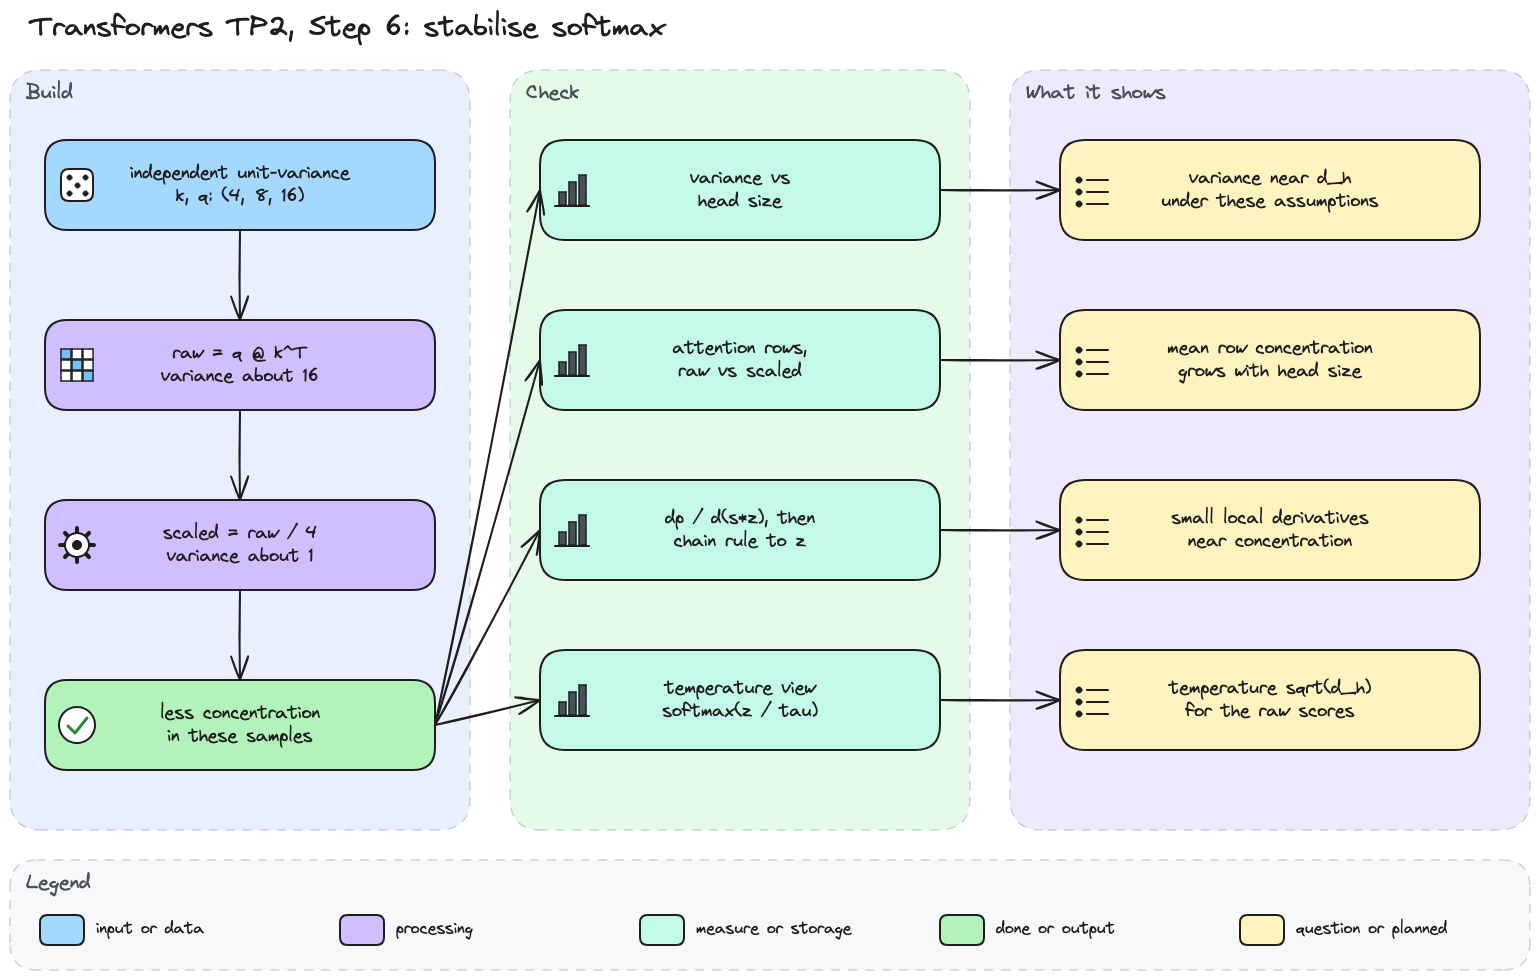

In [42]:
# Step 6 diagram: raw and scaled scores, and the experiments behind my conclusion.
display(Image(filename='diagrams/transformers/tp2_step6.png', width=900))

In [43]:
# Why divide by sqrt(head_size)? The variance of raw and scaled scores for random keys and queries.
torch.manual_seed(1337)
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)

raw = q @ k.transpose(-2, -1)
scaled = raw * head_size**-0.5

print(raw.var(), scaled.var())

tensor(18.4436) tensor(1.1527)


The raw variance is 18.44 and the scaled variance is 1.15. Under independent, zero-mean, unit-variance components, the sum of 16 query-key products has expected variance 16.

Dividing the scores by √16 = 4 divides their variance by 16. The measured relation 18.44 / 16 = 1.15 follows from that scaling, while the difference from 16 and 1 reflects the finite sample.

There are 256 score entries, but they share queries or keys and are not all independent observations. I next keep one short score vector fixed and multiply it by 8 to isolate the softmax response.

In [44]:
# What does a larger spread do to softmax? The same five scores, then multiplied by 8.
z = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print(torch.softmax(z, dim=-1))
print(torch.softmax(z * 8, dim=-1))

tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


The original weights range from 0.143 to 0.287. Multiplying the scores by 8 preserves their ranking, but the largest weight becomes 0.800 and the two smallest become 0.003.

Increasing the differences between scores concentrates this row. This supports the proposed mechanism without showing what a trained head would do. I next check the variance argument over the existing head sizes under the same standard-normal assumptions.

d_h = 4: raw variance 4.08, scaled variance 1.021
d_h = 16: raw variance 16.14, scaled variance 1.009
d_h = 64: raw variance 64.57, scaled variance 1.009
d_h = 256: raw variance 254.57, scaled variance 0.994


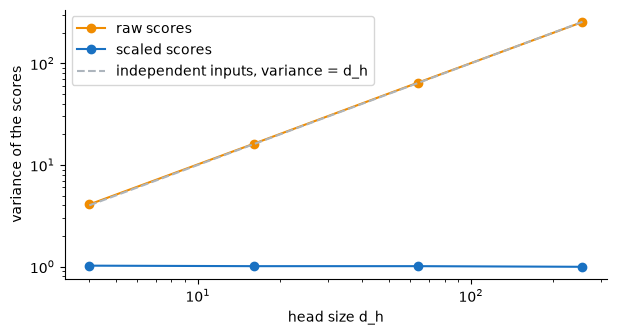

In [45]:
# Does the raw variance follow the head size? Raw and scaled variances for several d_h.
torch.manual_seed(RANDOM_STATE)
HEAD_SIZES = [4, 16, 64, 256]
samples = {}
for d in HEAD_SIZES:
    samples[d] = torch.randn(1000, T, d) @ torch.randn(1000, T, d).transpose(-2, -1)
    print(f'd_h = {d}: raw variance {samples[d].var():.2f}, '
          f'scaled variance {(samples[d] * d**-0.5).var():.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(HEAD_SIZES, [samples[d].var() for d in HEAD_SIZES], marker='o', color='#f08c00',
        label='raw scores')
ax.plot(HEAD_SIZES, [(samples[d] * d**-0.5).var() for d in HEAD_SIZES], marker='o',
        color='#1971c2', label='scaled scores')
ax.plot(HEAD_SIZES, HEAD_SIZES, linestyle='--', color='#adb5bd',
        label='independent inputs, variance = d_h')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('head size d_h')
ax.set_ylabel('variance of the scores')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Across these samples, raw variance increases from 4.08 at head size 4 to 254.57 at head size 256. Scaled variance stays between 0.994 and 1.021, near the theoretical reference of 1.

This supports division by √d_h under the synthetic assumptions. It does not guarantee unit variance for arbitrary projected or trained keys and queries.

For each size, I now compare softmax before and after scaling the same sampled scores. I use only the final row so every distribution has eight visible positions.

Final rows per head size: 1000
d_h = 4: mean largest weight raw 0.54, scaled 0.35, mean entropy raw 1.27, scaled 1.74
d_h = 16: mean largest weight raw 0.75, scaled 0.36, mean entropy raw 0.67, scaled 1.72
d_h = 64: mean largest weight raw 0.87, scaled 0.36, mean entropy raw 0.32, scaled 1.72
d_h = 256: mean largest weight raw 0.94, scaled 0.36, mean entropy raw 0.14, scaled 1.73
Entropy of a uniform last row, ln(8): 2.08


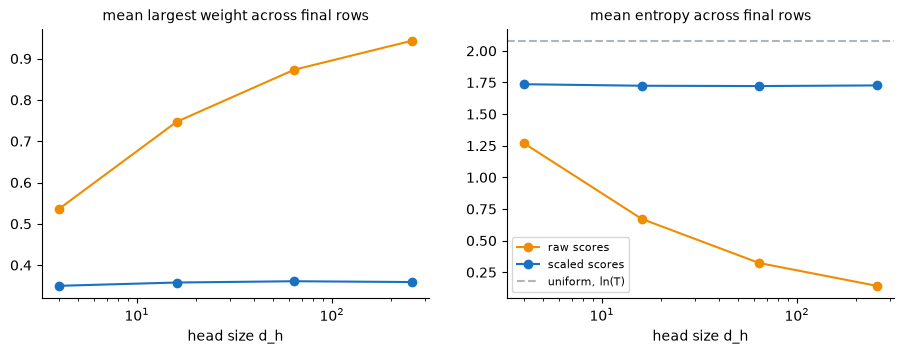

In [46]:
# What does each version do to the attention rows? Masked softmax of raw and scaled scores.
print(f'Final rows per head size: {len(samples[HEAD_SIZES[0]])}')
largest = {'raw': [], 'scaled': []}
spread = {'raw': [], 'scaled': []}
for d in HEAD_SIZES:
    for name, scores in (('raw', samples[d]), ('scaled', samples[d] * d**-0.5)):
        rows = F.softmax(scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)[:, -1]
        largest[name].append(rows.max(dim=-1).values.mean().item())
        spread[name].append(-(rows * torch.log(rows.clamp_min(1e-12))).sum(dim=-1).mean().item())
    print(f'd_h = {d}: mean largest weight raw {largest["raw"][-1]:.2f}, '
          f'scaled {largest["scaled"][-1]:.2f}, '
          f'mean entropy raw {spread["raw"][-1]:.2f}, scaled {spread["scaled"][-1]:.2f}')
print(f'Entropy of a uniform last row, ln({T}): {math.log(T):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, values, title in ((axes[0], largest, 'mean largest weight across final rows'),
                          (axes[1], spread, 'mean entropy across final rows')):
    ax.plot(HEAD_SIZES, values['raw'], marker='o', color='#f08c00', label='raw scores')
    ax.plot(HEAD_SIZES, values['scaled'], marker='o', color='#1971c2', label='scaled scores')
    ax.set_xscale('log')
    ax.set_xlabel('head size d_h')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(math.log(T), linestyle='--', color='#adb5bd', label='uniform, ln(T)')
axes[1].legend(fontsize=8)
plt.show()

The printed values average statistics over 1,000 final rows at each head size. The largest-weight statistic averages each row's maximum, and the entropy statistic averages each row's entropy. A uniform eight-position row has entropy ln(8) = 2.08.

For raw scores, the mean largest weight rises from 0.54 to 0.94 as the head size grows from 4 to 256. Mean entropy falls from 1.27 to 0.14. Scaling keeps the mean largest weight between 0.35 and 0.36 and mean entropy between 1.72 and 1.74.

At head size 16, the mean raw maximum is 0.75 in this synthetic experiment. This is not the weight of the projected head from section 5. The next check asks how concentration affects softmax's local sensitivity.

scale 0.25: largest weight 0.221, Jacobian norm 0.4002
scale 1: largest weight 0.287, Jacobian norm 0.4033
scale 2: largest weight 0.383, Jacobian norm 0.4095
scale 4: largest weight 0.564, Jacobian norm 0.4016
scale 8: largest weight 0.800, Jacobian norm 0.2825
scale 16: largest weight 0.959, Jacobian norm 0.0759
scale 32: largest weight 0.998, Jacobian norm 0.0033


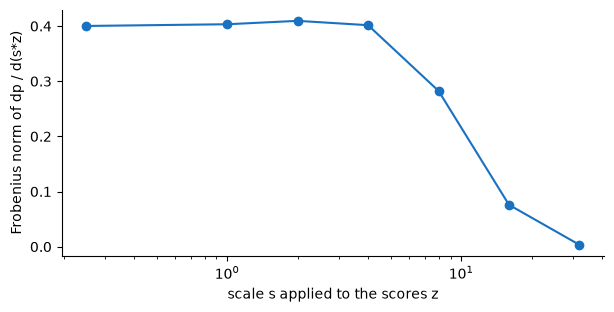

In [47]:
# Measure local softmax sensitivity to its input scores as concentration increases.
SCALES = [0.25, 1, 2, 4, 8, 16, 32]
jacobian_norms = []
for s in SCALES:
    p = torch.softmax(z * s, dim=-1)
    jacobian_norms.append(torch.linalg.matrix_norm(torch.diag(p) - torch.outer(p, p)).item())
    print(f'scale {s}: largest weight {p.max():.3f}, Jacobian norm {jacobian_norms[-1]:.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(SCALES, jacobian_norms, marker='o', color='#1971c2')
ax.set_xscale('log')
ax.set_xlabel('scale s applied to the scores z')
ax.set_ylabel('Frobenius norm of dp / d(s*z)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The Jacobian `diag(p) - p pᵀ` describes how probabilities change when the scores entering softmax change. Its Frobenius norm summarises those local derivatives. It is not itself a training gradient.

The norm rises slightly from 0.4002 to 0.4095 before falling to 0.0033 at scale 32. At that last scale, the largest weight is 0.998. The response becomes small near this concentrated distribution, rather than decreasing at every scale.

The plotted derivative is with respect to the scaled scores. To relate it to the original scores, I must also include the multiplier from the chain rule. I check that distinction on detached copies below.

In [49]:
# Check the derivative with respect to scaled scores and then to the original scores.
for demo_scale in (1.0, 32.0):
    demo_input = z.detach().clone().requires_grad_(True)
    demo_logits = demo_input * demo_scale
    demo_probs = demo_logits.softmax(dim=-1)
    demo_jacobian = torch.diag(demo_probs.detach()) - torch.outer(
        demo_probs.detach(), demo_probs.detach())
    demo_grad_logits, demo_grad_input = torch.autograd.grad(
        demo_probs[4], (demo_logits, demo_input))
    assert torch.allclose(demo_grad_logits, demo_jacobian[4], atol=1e-6)
    assert torch.allclose(demo_grad_input, demo_scale * demo_jacobian[4], atol=1e-6)
    print(f'scale {demo_scale:g}: p[4] = {demo_probs[4].item():.6f}, '
          f'dp[4]/d(s*z)[4] = {demo_grad_logits[4].item():.6f}, '
          f'dp[4]/dz[4] = {demo_grad_input[4].item():.6f}')

scale 1: p[4] = 0.287173, dp[4]/d(s*z)[4] = 0.204705, dp[4]/dz[4] = 0.204705
scale 32: p[4] = 0.998338, dp[4]/d(s*z)[4] = 0.001659, dp[4]/dz[4] = 0.053081


For the chosen probability, the derivative with respect to its own softmax input is p × (1 − p). It falls from about 0.204705 at scale 1 to 0.001659 at scale 32 in this example.

At scale 32, the derivative with respect to the original score is about 0.053081 because the chain rule includes the multiplier. The assertions verify both derivatives. This prevents me from treating the plotted Jacobian as the complete gradient path.

These calculations use detached copies and apply no parameter update. A training gradient would also depend on the loss and the rest of the model. I finish by expressing the same score scaling as a temperature.

temperature 4.0: [0.2, 0.185, 0.21, 0.185, 0.221]
temperature 1.0: [0.192, 0.143, 0.235, 0.143, 0.287]
temperature 0.25: [0.114, 0.034, 0.253, 0.034, 0.564]
temperature 0.125: [0.033, 0.003, 0.162, 0.003, 0.8]


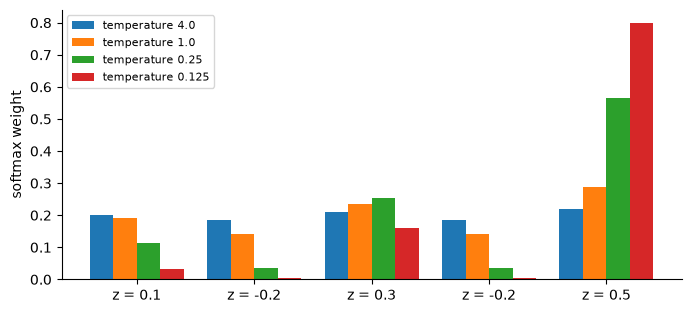

In [51]:
# Dividing by sqrt(d_h) as a temperature: softmax of z divided by several temperatures.
TEMPERATURES = [4.0, 1.0, 0.25, 0.125]  # z * 8 corresponds to a temperature of 1/8
positions = torch.arange(len(z))
fig, ax = plt.subplots(figsize=(8, 3.5))
for k_index, tau in enumerate(TEMPERATURES):
    weights_tau = torch.softmax(z / tau, dim=-1)
    print(f'temperature {tau}: {[round(w, 3) for w in weights_tau.tolist()]}')
    ax.bar(positions + 0.2 * (k_index - 1.5), weights_tau, 0.2, label=f'temperature {tau}')
ax.set_xticks(positions, [f'z = {score:.1f}' for score in z.tolist()])
ax.set_ylabel('softmax weight')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

At temperature 4, the weights range from 0.185 to 0.221. At temperature 0.125, the largest reaches 0.8. With a unique maximum, lowering temperature towards zero concentrates the distribution on that maximum.

This is the same score transformation I considered alongside greedy generation in TP1. Its role here is inside attention, before mixing values, rather than choosing a generated character.

Dividing a fixed raw score row by √d_h is equivalent to setting its temperature to √d_h. The synthetic comparisons show reduced concentration across the tested sizes. They do not guarantee useful weights, nonzero computed probabilities or successful learning for every input.

> *My conclusion:*
>
> The synthetic variance experiments support the scaling argument under independent, zero-mean, unit-variance components. Scaling each sample keeps its variance near 1 and reduces the concentration of the final-row distributions in these tests.
>
> My original hypothesis is supported within that setting. It does not describe every initialisation or establish what training will learn. The projected head in section 5 is a different experiment.
>
> The derivative example shows why a nearly concentrated softmax can attenuate changes in its input scores. Actual parameter gradients also depend on the upstream objective, the projections and the scaling factor. No optimiser update or training outcome was measured here.

## Summary

I return to the hypotheses with the scope of each check in mind. The first three versions should reproduce one operation, while the head changes both the weights and the vectors being mixed.

I compare their causal constraints on the same input next. Matching those constraints is a requirement for the head, even though its output need not equal the averages.

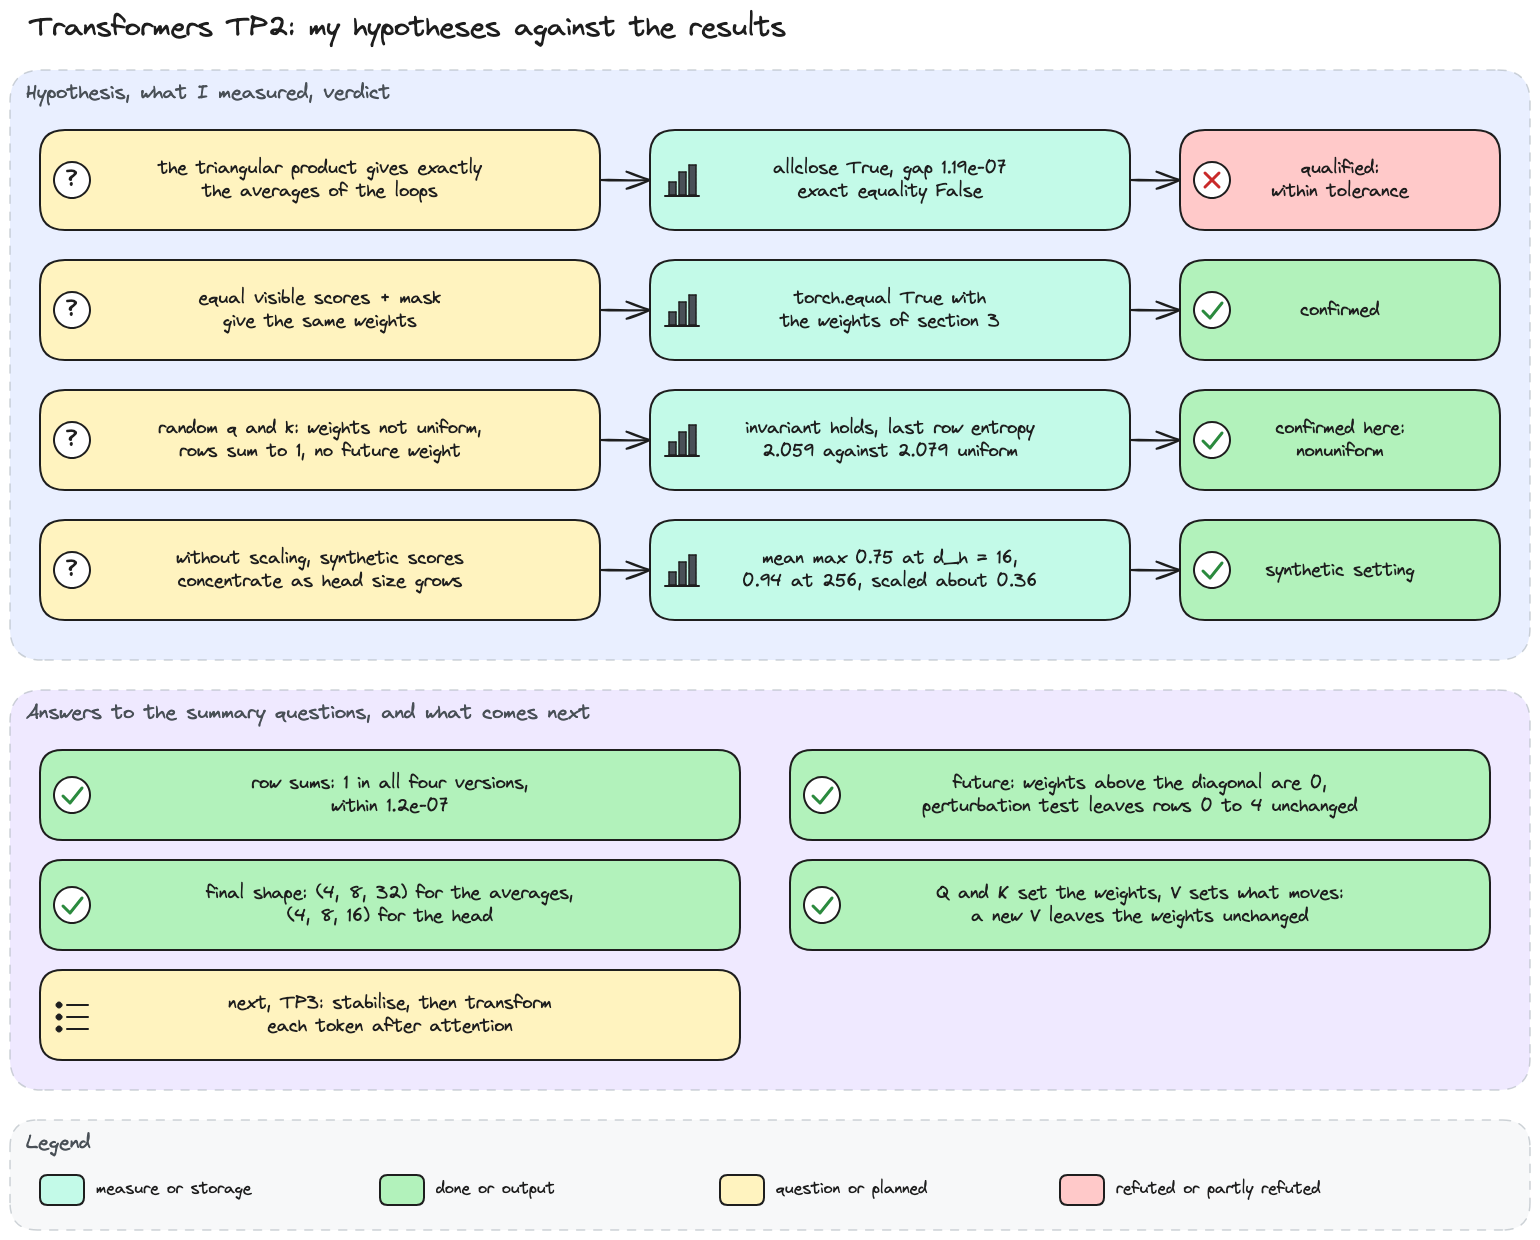

In [52]:
# Summary diagram: my hypotheses, what I measured, my verdicts, and the summary answers.
display(Image(filename='diagrams/transformers/tp2_summary.png', width=900))

In [53]:
# Tools: the four versions as functions of x, each returning its output and its weights.
def head_mix(x: torch.Tensor, q: nn.Module = query, k: nn.Module = key,
             v: nn.Module = value) -> tuple[torch.Tensor, torch.Tensor]:
    """The head of section 5: masked softmax of the scaled q · kᵀ, then a mix of the values."""
    scores = q(x) @ k(x).transpose(-2, -1) * head_size**-0.5
    wei = F.softmax(scores.masked_fill(tril[:T, :T] == 0, float('-inf')), dim=-1)
    return wei @ v(x), wei


# The weights of section 4, rebuilt because section 5 reused the name wei
uniform = F.softmax(torch.zeros(T, T).masked_fill(tril == 0, float('-inf')), dim=-1)

VERSIONS = {
    # the loops applied to the identity reveal the weights they use
    'two loops': lambda x: (loop_mean(x), loop_mean(torch.eye(T).expand(len(x), T, T))),
    'triangular product': lambda x: (weights @ x, weights.expand(len(x), T, T)),
    'mask and softmax': lambda x: (uniform @ x, uniform.expand(len(x), T, T)),
    'attention head': head_mix,
}

In [54]:
# Do the four versions keep the invariant? Row sums, future weights and final shape on x.
print(f'x: {tuple(x.shape)}')
for name, version in VERSIONS.items():
    output, version_weights = version(x)
    gap = (version_weights.sum(dim=-1) - 1).abs().max().item()
    future = version_weights.triu(1).abs().max().item()
    print(f'{name}: output {tuple(output.shape)}, row sums within {gap:.1e} of 1, '
          f'largest future weight {future}')

x: (4, 8, 32)
two loops: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
triangular product: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
mask and softmax: output (4, 8, 32), row sums within 1.2e-07 of 1, largest future weight 0.0
attention head: output (4, 8, 16), row sums within 1.2e-07 of 1, largest future weight 0.0


All four versions have row sums within 1.2e-07 of 1 and zero weights above the diagonal on this input. The averages return (4, 8, 32), while the head returns (4, 8, 16) because its values have 16 channels.

A row sum of 1 alone would also allow future positions to receive weight. I therefore check the masked entries separately and perturb a future input next. This asks whether the exclusion also holds through the complete output calculation.

two loops: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
triangular product: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
mask and softmax: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 1.67, 1.43, 1.25]
attention head: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 0.26, 0.51, 0.48]


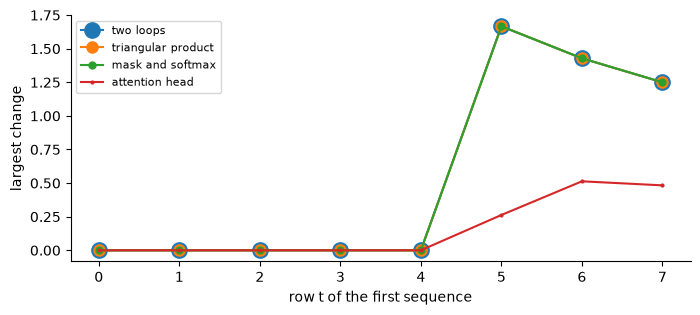

In [55]:
# Does any version read the future? Token 5 of the first sequence raised by 10, then rerun.
changed = x.clone()
changed[0, 5] += 10
moves = {}
for name, version in VERSIONS.items():
    moves[name] = (version(changed)[0][0] - version(x)[0][0]).abs().max(dim=1).values.detach()
    assert torch.equal(moves[name][:5], torch.zeros(5))
    print(f'{name}: largest change per row {[round(v, 2) for v in moves[name].tolist()]}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for index, (name, move) in enumerate(moves.items()):
    ax.plot(range(T), move, marker='o', markersize=11 - 3 * index, label=name)  # visible overlaps
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Changing token 5 leaves rows 0 to 4 unchanged in all four versions in this test. The three averages move later rows by 1.67, 1.43 and 1.25, matching the fixed coefficients applied to the added value.

The head's later changes are 0.26, 0.51 and 0.48. They do not decrease monotonically in this example because the perturbation affects both scores and values. Their magnitudes cannot be compared as evidence of better representations, since the head also changes channel size and projection.

The causal structure and this perturbation give complementary evidence. I next inspect the weight matrices directly to distinguish shared constraints from equal computations.

Weights read from the loops equal the weights of section 1: True
two loops, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
triangular product, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
mask and softmax, last row: [0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125]
attention head, last row: [0.084, 0.12, 0.108, 0.154, 0.109, 0.115, 0.156, 0.155]


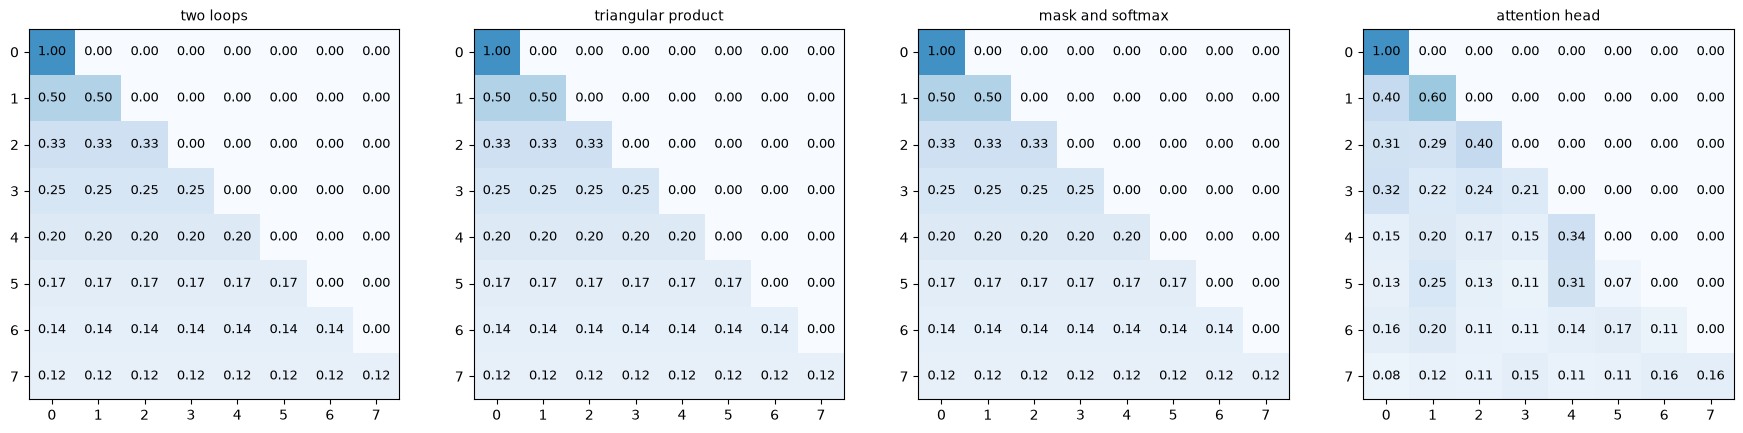

In [56]:
# The weights of the first sequence in each version, side by side. The last panel is wei[0].
loop_weights = VERSIONS['two loops'](x)[1][0]
print(f'Weights read from the loops equal the weights of section 1: '
      f'{torch.equal(loop_weights, weights)}')

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (name, version) in zip(axes, VERSIONS.items()):
    last = version(x)[1][0]
    print(f'{name}, last row: {[round(w, 3) for w in last[-1].tolist()]}')
    show_matrix(ax, last, name)
plt.show()

Applying the linear averaging operation to an identity matrix reveals its coefficients. Those coefficients equal the matrix from section 1 in this run.

The first three versions use the same weights, including 0.125 in every entry of the last row. The head retains the causal pattern but has last-row weights from 0.084 to 0.156.

I finish with the projection swaps on the same input. Replacing one projection at a time tests which outputs depend directly on it.

Another query layer: weights move by up to 0.255, output by up to 0.56
Another key layer: weights move by up to 0.554, output by up to 1.07
Another value layer: weights move by up to 0.000, output by up to 2.70


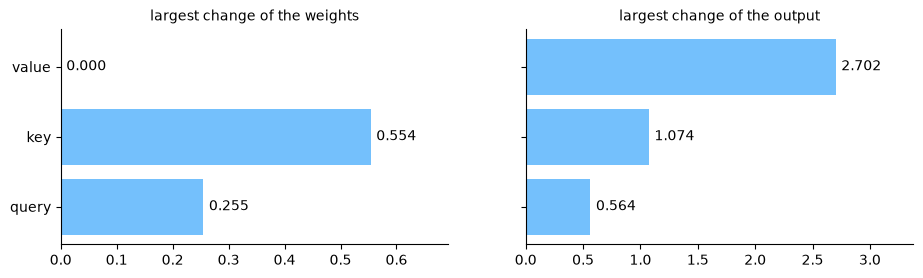

In [57]:
# Which layer sets what? Swap query, key or value for another random layer, one at a time.
torch.manual_seed(RANDOM_STATE)
# created in this order so the key and value layers are those of section 5
other_key, other_value, other_query = (nn.Linear(C, head_size, bias=False) for _ in range(3))
swaps = {'query': {'q': other_query}, 'key': {'k': other_key}, 'value': {'v': other_value}}
weight_moves, output_moves = [], []
for name, swap in swaps.items():
    swapped_out, swapped_wei = head_mix(x, **swap)
    weight_moves.append((swapped_wei - wei).abs().max().item())
    output_moves.append((swapped_out - out).abs().max().item())
    print(f'Another {name} layer: weights move by up to {weight_moves[-1]:.3f}, '
          f'output by up to {output_moves[-1]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for ax, values, title in ((axes[0], weight_moves, 'largest change of the weights'),
                          (axes[1], output_moves, 'largest change of the output')):
    bars = ax.barh(list(swaps), values, color='#74c0fc')
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=4)
    ax.set_xlim(0, max(values) * 1.25)
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

Replacing the query or key projection changes the weights by up to 0.255 or 0.554. Replacing only values leaves the weights unchanged and changes the output by up to 2.70.

This matches the separation in the formula. Queries and keys determine compatibility scores, while values carry the vectors combined by the resulting weights.

The different magnitudes describe these random replacements. They do not rank the importance of Q, K and V or measure the benefit of learning each projection.

> *My conclusion:*
>
> I can replace a fixed causal average with input-dependent weights while retaining normalised rows and excluding future positions. The head also projects the values it combines. These are mechanism checks on an untrained system.
>
> My hypotheses have the following outcomes:
>
> - The triangular product matches the loop means within tolerance. The observed difference revises my initial expectation of exact floating-point agreement.
> - Equal visible scores with the −∞ mask reproduce the triangular weights exactly in this run. The fully masked example also identifies a condition the construction must avoid.
> - Randomly initialised queries and keys give nonuniform weights while retaining the constraints. Their proximity to uniform does not contradict that hypothesis or establish usefulness.
> - Without scaling, the synthetic unit-variance inputs produce increasingly concentrated distributions as head size grows. This supports the scaling argument under its stated assumptions.
>
> My answers to the four summary questions of TP2:
>
> 1. All four versions have row sums within 1.2e-07 of 1 in the displayed check.
> 2. Their future weights are zero, and changing token 5 leaves rows 0 to 4 unchanged in the perturbation test.
> 3. The averages return (4, 8, 32). The head returns (B, T, d_h) = (4, 8, 16).
> 4. Q and K determine the weights, while V provides the vectors being combined. Replacing only V changes the output while keeping the weights fixed.
>
> This investigation gives me a more precise way to evaluate an implementation. I first choose a readable reference and state the invariants. I then change one part at a time and match each claim to what the comparison actually measures.
>
> I also need to distinguish mathematical identities, floating-point checks and empirical observations. A working causal head is a step towards a language model, but these tests provide no evidence of better text generation. TP3 next examines normalisation and transformations applied separately to each token.